# 模型的创建与调用


## 这篇笔记先回答什么？

LangChain 应用的第一步通常是选择一个聊天模型并调用它。本篇从模型放在哪里、如何配置认证信息开始，依次介绍专用模型类、OpenAI 兼容接口、`init_chat_model`、常用参数、本地 Ollama，以及 `invoke`、`stream`、`batch`、异步调用和 `config`。

课件示例使用多个供应商和课程时期的模型名。代码只用于说明调用结构，不会在 Notebook 中执行；真正运行时请使用当前供应商文档中可用的模型名和对应参数。


## 1. 模型调用的基本结构

早期 LangChain 常用 **Model I/O** 来描述一次模型调用：

~~~text
输入格式化 Format → 模型预测 Predict → 输出解析 Parse
Prompt Template       Model              Output Parser
~~~

现在聊天模型已经是主流。与“补全文本”的旧式模型相比，聊天模型以消息列表作为输入，能更自然地处理系统指令、用户消息、历史消息和工具调用。

LangChain 本身不提供模型权重，也不等于某一家模型服务。它依赖供应商集成包，负责用统一的 Runnable 接口连接这些模型。

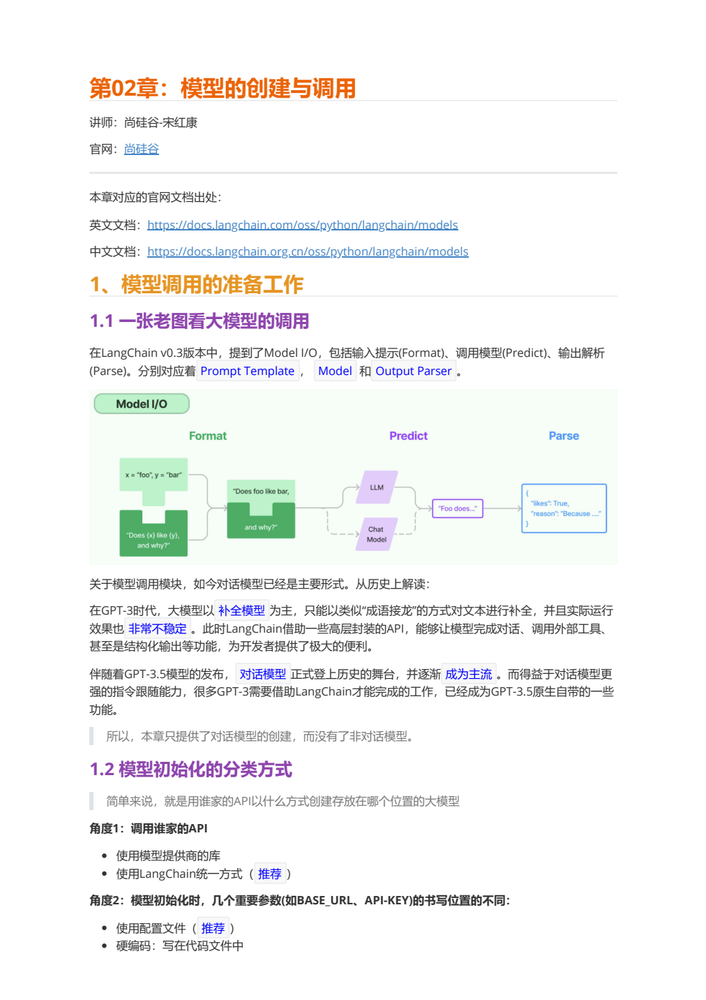


### 初始化模型时要做的三个选择

| 选择角度 | 常见选项 | 建议 |
| --- | --- | --- |
| 调用谁家的 API | 供应商专用类 / LangChain 统一入口 | 新项目优先理解统一入口，同时掌握专用类的排错方式 |
| 配置写在哪里 | `.env` 或密钥管理系统 / 硬编码 | 使用配置文件，密钥不要写进代码和 Git |
| 模型部署在哪里 | 云端 API / 本地模型 | 云端适合快速接入，本地适合离线、隐私或成本控制 |

无论选择哪种方式，初始化都需要知道模型名、认证信息和请求地址；兼容 OpenAI 协议的平台还需要 `base_url`。


## 2. 准备依赖与环境变量

课程把主要依赖统一写入 `requirements.txt`，这样所有章节使用同一套版本，减少包之间的兼容问题。

~~~bash
conda activate langchain1.2
pip install -r requirements.txt
~~~

如果只想尝试当前章节，也可以按供应商安装对应集成包，例如 `langchain-deepseek`、`langchain-openai`、`langchain-community`、`langchain-openrouter` 和 `langchain-ollama`。集成包的名称和版本应以当前项目依赖文件为准。


### 用 `.env` 管理密钥

项目根目录可以创建 `.env`：

~~~dotenv
DEEPSEEK_API_KEY=你的密钥
DEEPSEEK_BASE_URL=https://api.deepseek.com
~~~

代码中加载它：

~~~python
import os
from dotenv import load_dotenv

load_dotenv(override=True)
api_key = os.getenv("DEEPSEEK_API_KEY")
~~~

把 `.env` 加入 `.gitignore`。如果密钥已经提交到仓库，应立即撤销旧密钥并重新生成，不能只删除本地文件。


## 3. 方式一：使用供应商专用模型类

LangChain 为很多供应商提供专用聊天模型类，例如 `ChatDeepSeek`、`ChatOpenAI`、`ChatAnthropic`、`ChatOllama`、`ChatTongyi` 和 `ChatZhipuAI`。

专用类的优点是参数和供应商能力更直观；缺点是不同类的参数命名、默认地址和依赖包可能不完全一致。遇到初始化错误时，先看当前集成包的 API Reference，不要把一个供应商的参数名直接套给另一个供应商。

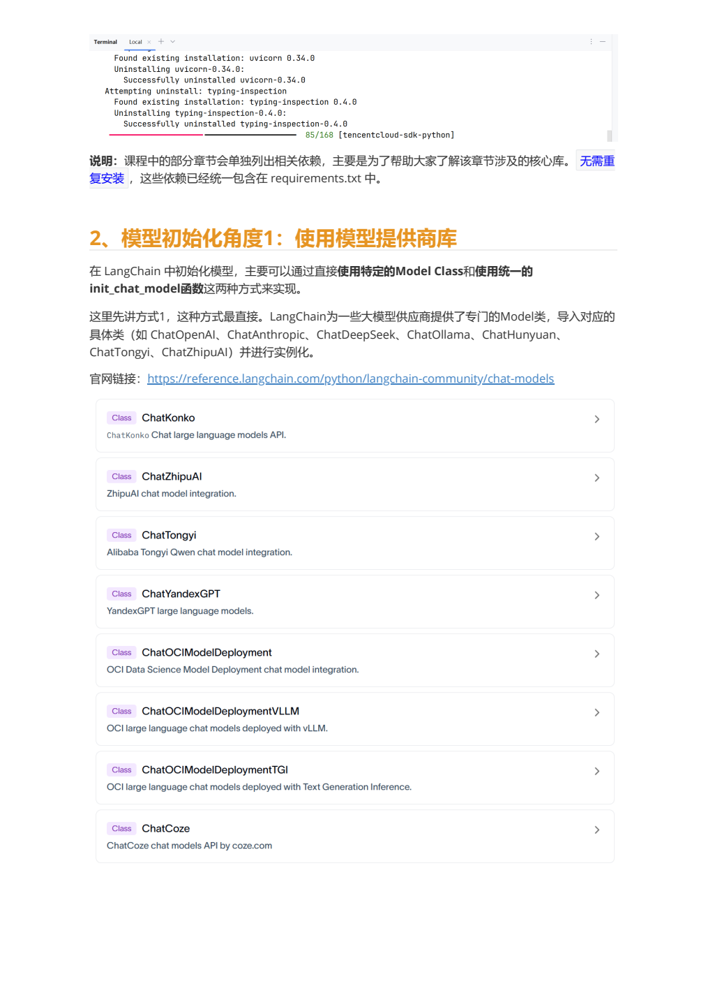


### DeepSeek：从环境变量初始化

课程展示了显式传入密钥和地址的写法，以及依赖环境变量自动读取的写法。优先使用后者：

~~~python
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
)

response = model.invoke("请用一句话介绍你自己")
print(response.content)
~~~

如果当前版本的集成类要求显式参数，可以按该版本文档传入 `api_key`、`api_base` 或 `base_url`。课程资料中的参数名属于课程依赖版本，不能假设所有版本完全相同。

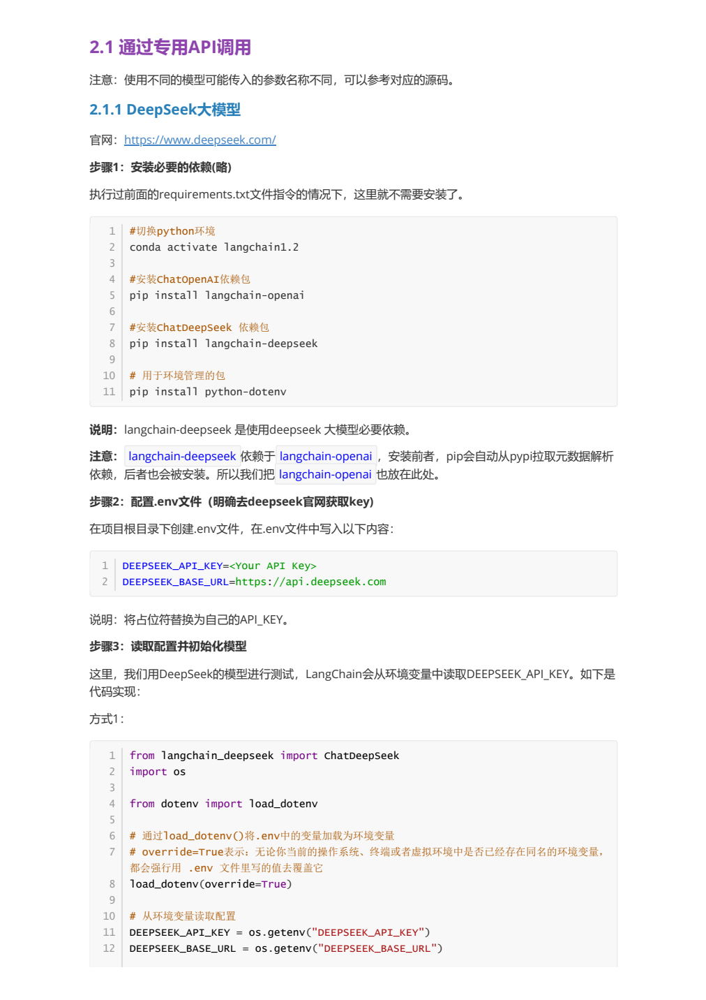

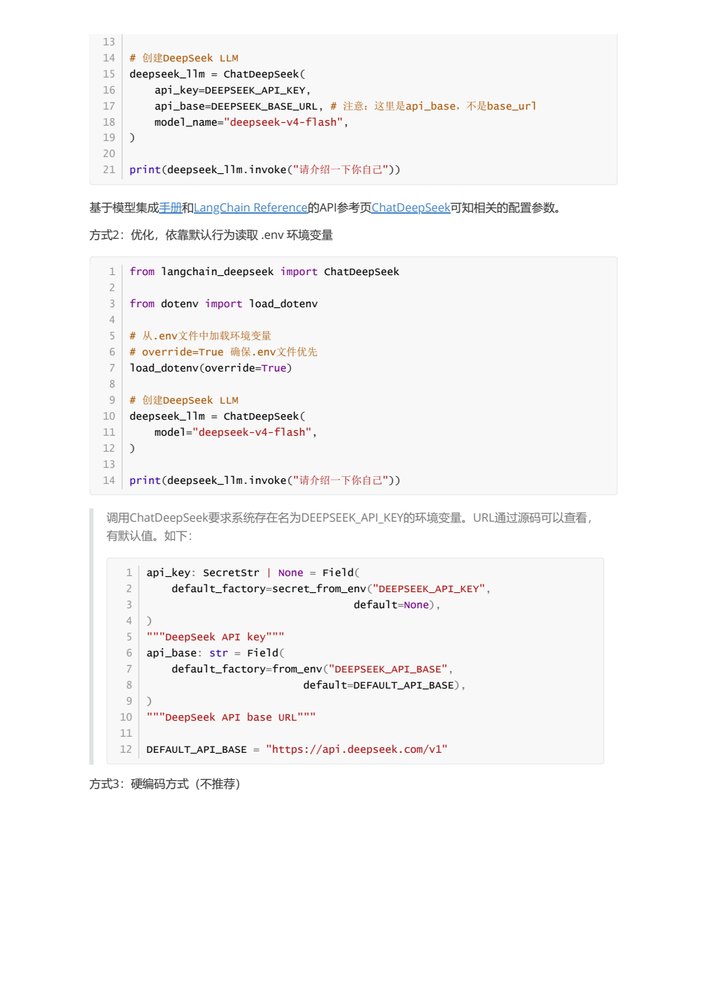


### 其他供应商的专用类

以智谱和通义为例，初始化前要安装各自的集成依赖，并使用它们规定的环境变量：

~~~python
from dotenv import load_dotenv
from langchain_community.chat_models import ChatZhipuAI, ChatTongyi

load_dotenv(override=True)

zhipu = ChatZhipuAI(
    model="glm-5.1",
    api_key=None,  # 也可以让集成类从环境变量读取
)

tongyi = ChatTongyi(
    model="qwen-plus",
)
~~~

通义的专用 SDK 与 OpenAI 兼容接口是两条不同路径。使用 `ChatTongyi` 时不要把只为兼容接口准备的 `DASHSCOPE_BASE_URL` 误传进去；如果走兼容接口，应改用 `ChatOpenAI` 并按兼容接口文档设置地址。

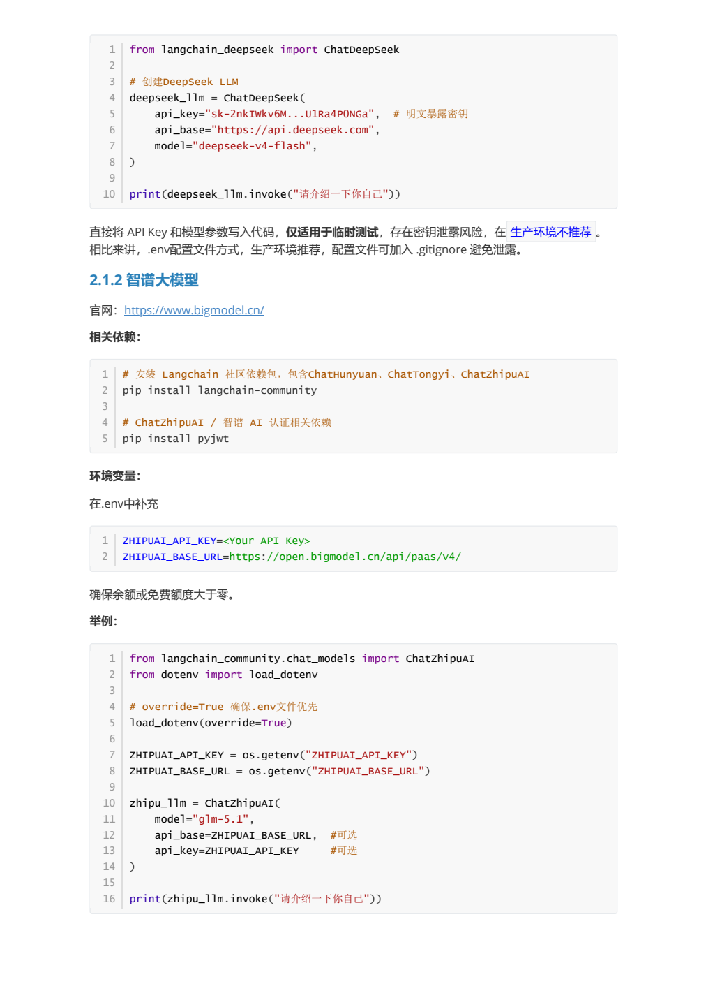

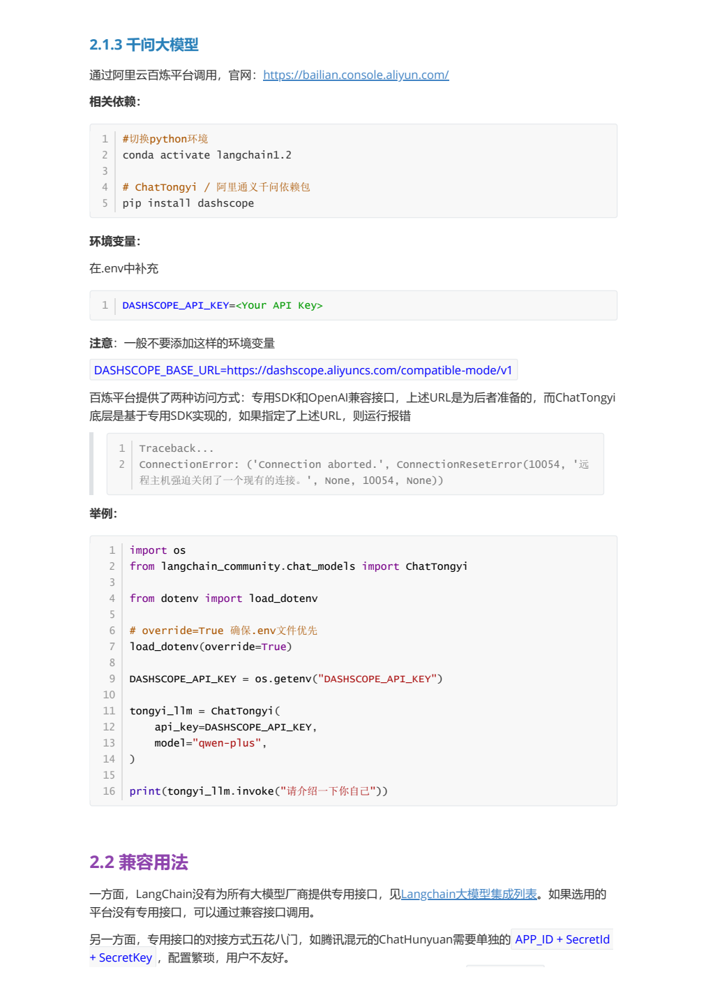


## 4. 方式二：使用 OpenAI 兼容接口

很多平台提供 OpenAI 风格的聊天接口。只要请求格式兼容，就可以使用 `ChatOpenAI`，通过 `base_url` 把请求发送到目标平台。

这不表示目标模型变成了 OpenAI 模型；它只是复用同一套请求协议。模型名、认证变量、计费方式、支持的参数和工具能力仍由实际平台决定。

~~~python
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv(override=True)

model = ChatOpenAI(
    model="deepseek-v4-flash",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
)

response = model.invoke("1 + 1 = ？")
print(response.content)
~~~

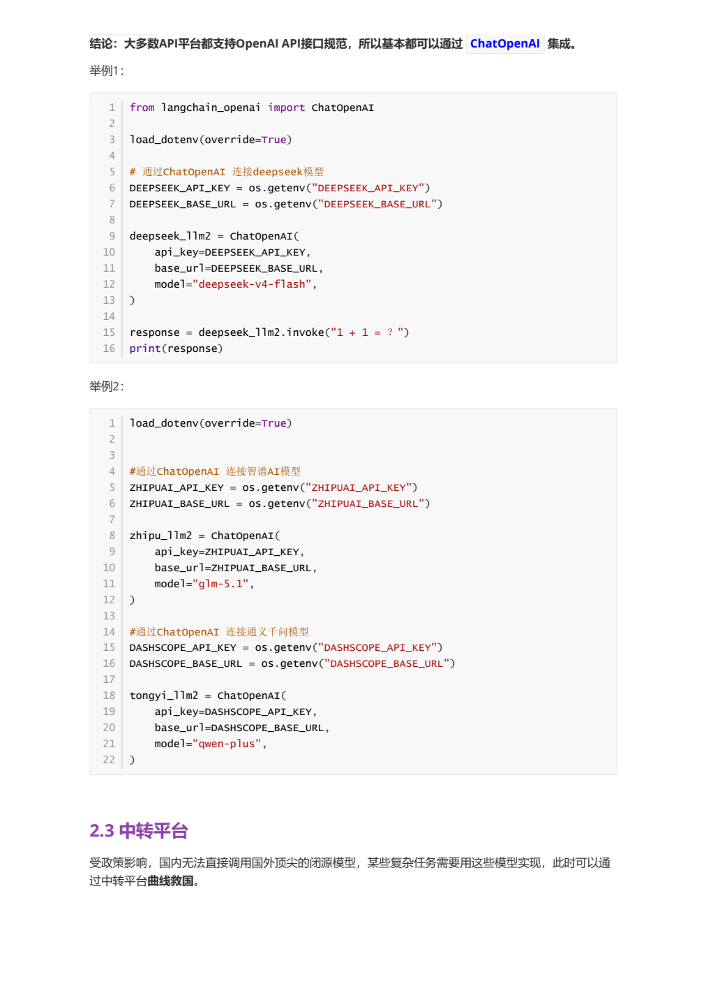


### OpenRouter 与其他中转平台

OpenRouter 等聚合平台用一个兼容入口连接多个模型，适合做模型对比或在一个应用中切换模型。课程也介绍了没有专用 LangChain 集成的平台，可以直接使用 `ChatOpenAI`。

~~~python
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
import os

load_dotenv(override=True)

model = ChatOpenAI(
    model="deepseek/deepseek-v4-flash",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url=os.getenv("OPENROUTER_API_BASE"),
)
~~~

如果平台有专用类，也可以使用专用类，例如 `ChatOpenRouter`。选择时优先考虑当前 SDK 是否维护、需要哪些额外能力，以及项目是否希望统一使用 OpenAI 兼容协议。

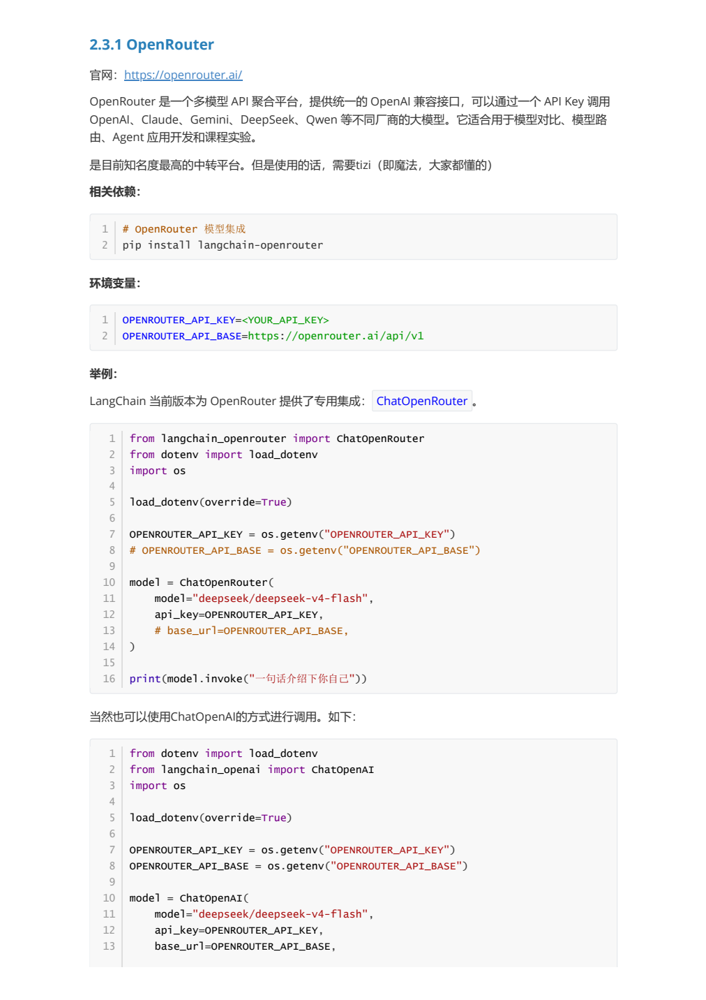

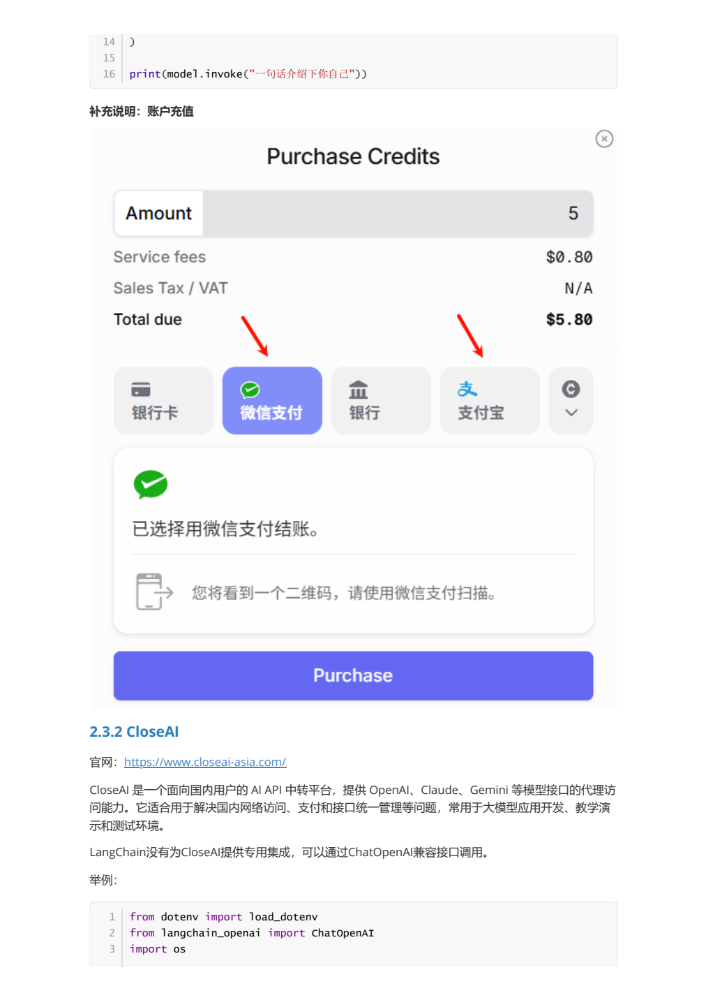


## 5. 方式三：`init_chat_model` 统一初始化

`init_chat_model` 是 LangChain 1.x 提供的统一入口。它根据模型标识和 `model_provider` 选择底层集成类，适合在应用中切换模型或把模型配置放到外部配置文件。

~~~python
from langchain.chat_models import init_chat_model

model = init_chat_model(
    model="deepseek:deepseek-v4-flash",
    api_key="从环境变量读取",
    temperature=0.2,
)
~~~

模型名可以写成 `provider:model_name`；也可以单独传 `model_provider`。如果供应商无法自动推断，就必须显式指定。

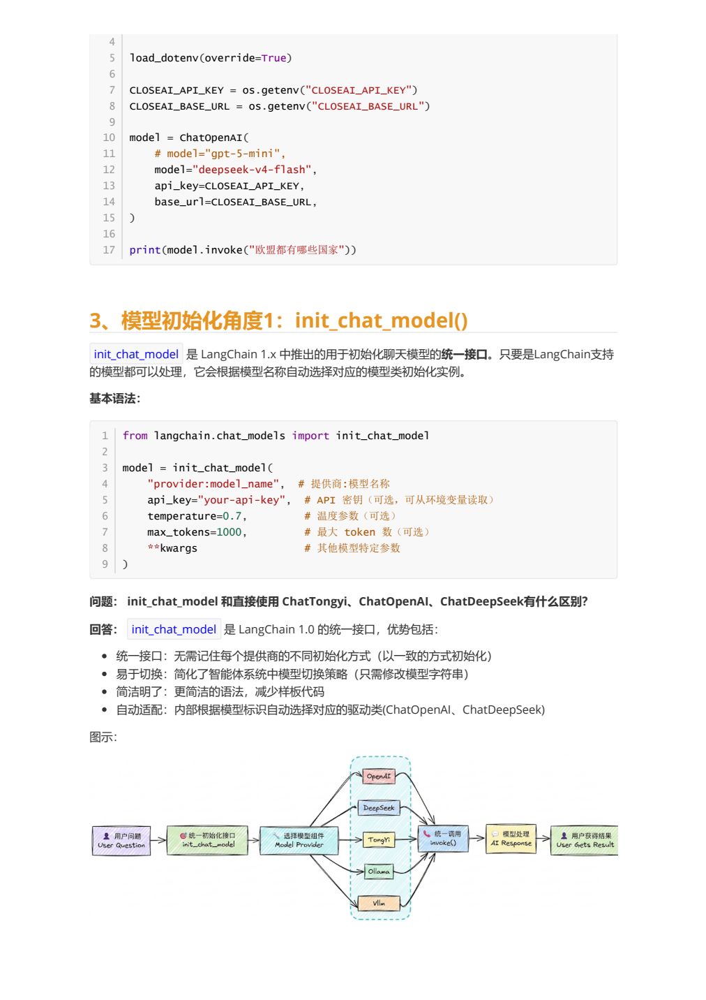


### `init_chat_model` 的切换价值

| 方式 | 代码变化 | 适合场景 |
| --- | --- | --- |
| 直接使用 `ChatDeepSeek` 等专用类 | 更换供应商通常要改导入和构造参数 | 需要供应商专有能力，或正在排查集成细节 |
| 使用 `ChatOpenAI` 兼容接口 | 更换兼容平台主要修改地址、密钥和模型名 | 多个平台遵循同一协议 |
| 使用 `init_chat_model` | 主要修改 `model`、`model_provider` 或外部配置 | Agent、评测和多模型路由 |

例如：

~~~python
from langchain.chat_models import init_chat_model

model = init_chat_model(
    model="qwen-plus",
    model_provider="openai",  # 目标平台提供 OpenAI 兼容接口时
    api_key="从环境变量读取",
    base_url="https://兼容接口地址/v1",
)
~~~

这里的 `model_provider="openai"` 表示使用 OpenAI 协议适配器，不代表模型提供商变成了 OpenAI。


## 6. 模型初始化的常用参数

| 参数 | 作用 | 使用提醒 |
| --- | --- | --- |
| `model` | 具体模型名 | 必须是目标平台支持的名称 |
| `model_provider` | 选择 LangChain 集成 | `provider:model` 已写前缀时通常可以推断 |
| `api_key` | 认证密钥 | 优先从环境变量或密钥服务读取 |
| `base_url` | API 请求地址 | 兼容接口和中转平台常用 |
| `temperature` | 输出随机性 | 低温适合抽取、分类和代码；高温适合创作 |
| `max_tokens` | 限制输出长度 | 具体含义由供应商和 API 版本决定 |
| `timeout` | 请求超时时间 | 线上服务应设置合理值 |
| `max_retries` | 失败重试次数 | 重试不能替代限流和幂等设计 |

温度只是采样参数，不会让模型“更聪明”。课程给出的经验区间是：0.0～0.3 偏稳定，0.5～0.7 平衡，0.8 以上偏创意；实际范围和效果由模型服务决定。

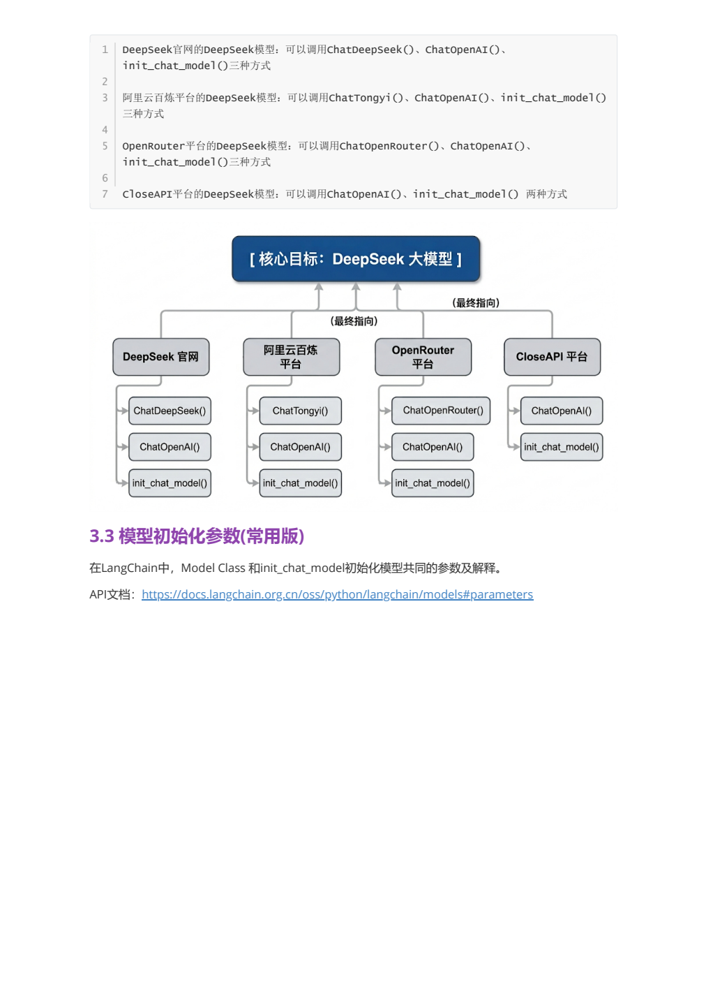

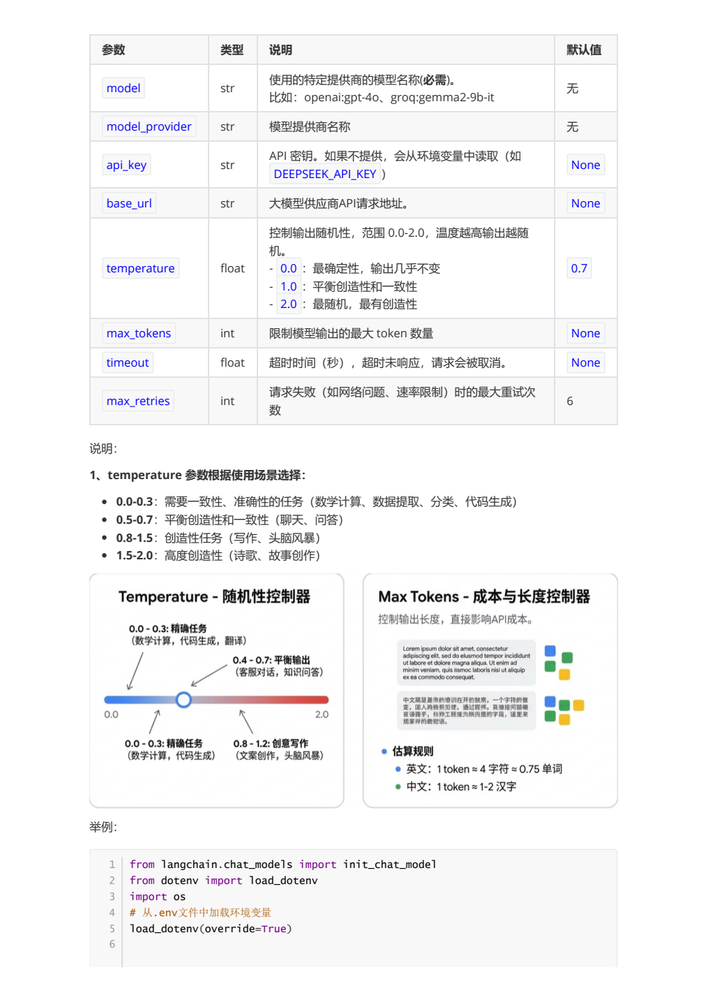


### 参数传递的边界

模型初始化参数决定一个模型实例的默认行为；调用时的 `config` 可以为单次运行附加运行名、标签、并发限制和可配置字段。两者不要混成一层。

如果供应商支持某个字段，但 LangChain 的模型类没有把它列为一等参数，可以根据集成文档使用 `model_kwargs` 或 `extra_body` 透传：

~~~python
model = init_chat_model(
    model="deepseek:deepseek-v4-flash",
    model_kwargs={"某个兼容 API 字段": "值"},
    extra_body={"供应商扩展字段": {"enabled": True}},
)
~~~

透传字段必须查供应商 API 文档；不要把不支持的字段随意塞进去。工具调用等能力优先使用 LangChain 提供的标准工具接口。


## 7. 本地模型：Ollama

Ollama 可以在本机管理和运行开源模型，适合离线实验、隐私数据和没有云端密钥的场景。它仍然需要本机有足够的内存、磁盘和计算资源；本地运行不等于没有成本。

基本流程：

1. 安装 Ollama；
2. 下载一个模型；
3. 确认 Ollama 服务运行；
4. 用 `ChatOllama` 连接本地模型。

~~~bash
ollama pull deepseek-r1:1.5b
ollama list
ollama run deepseek-r1:1.5b
~~~

模型文件很大，下载目录应预留足够空间。

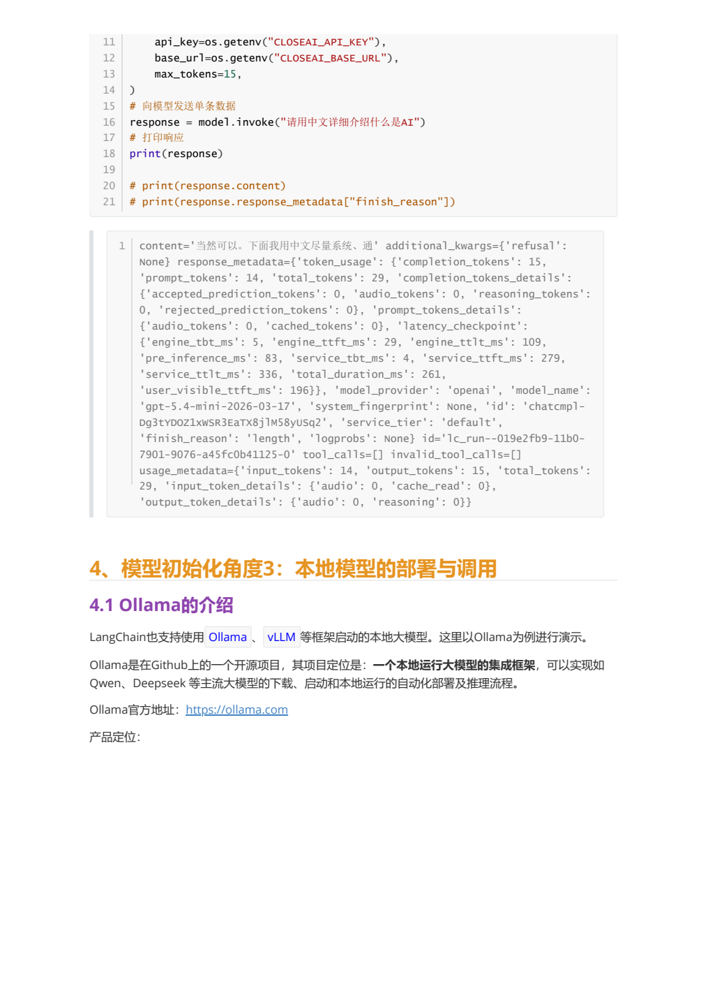

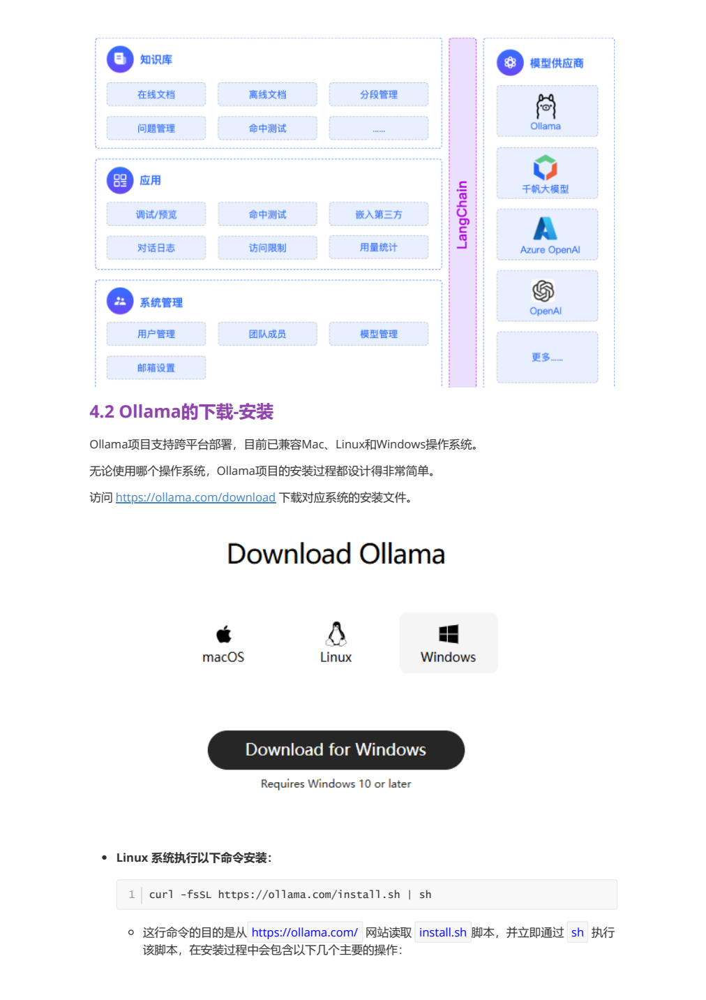

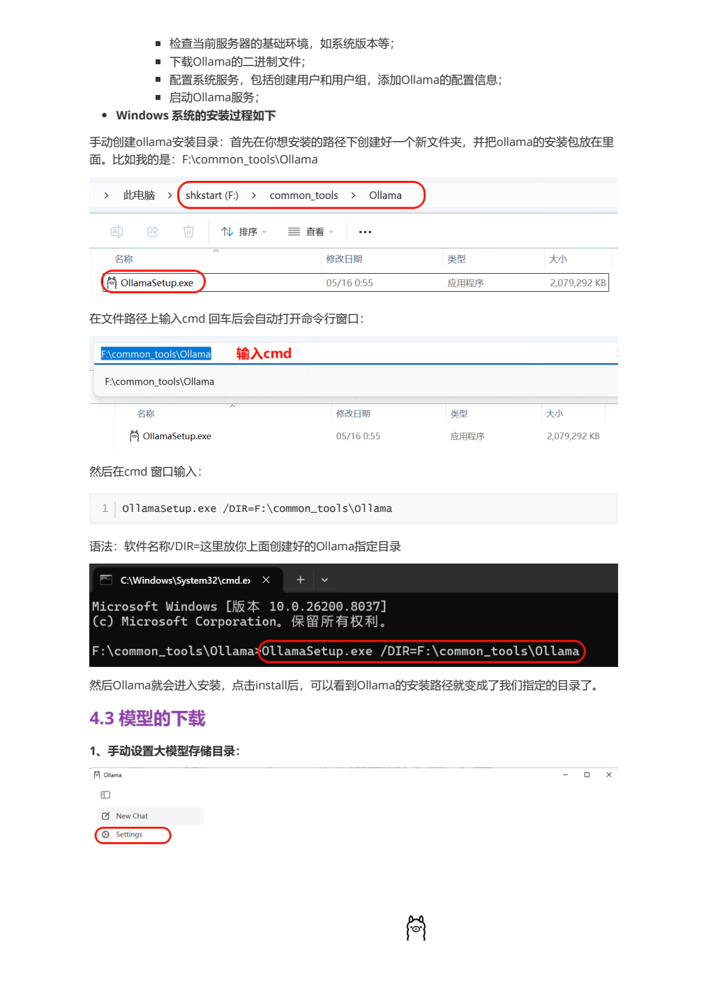

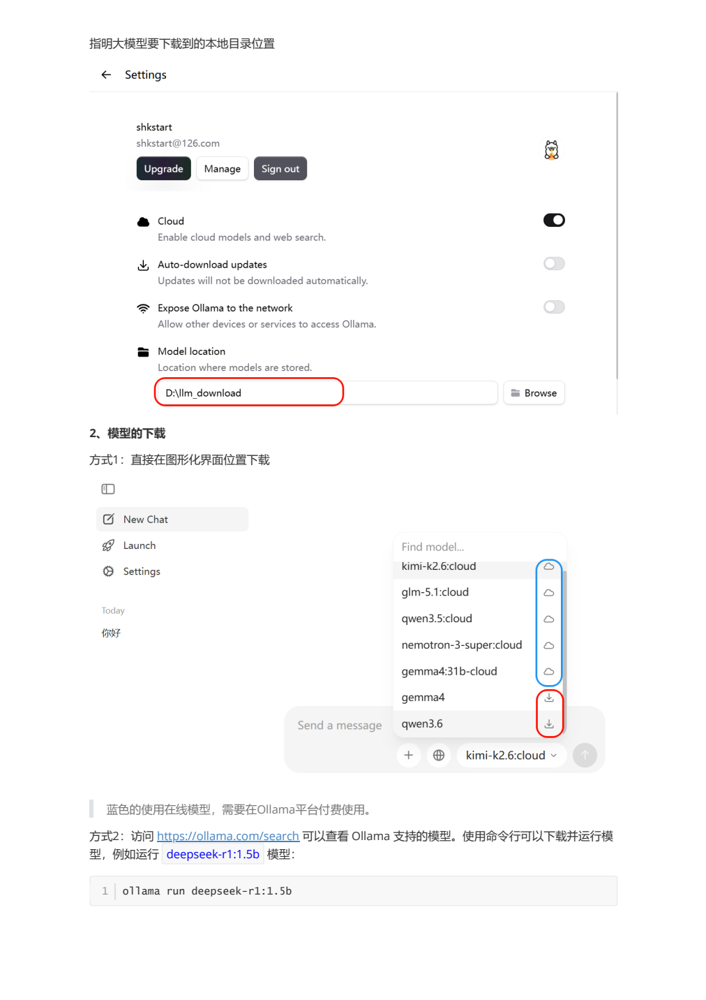

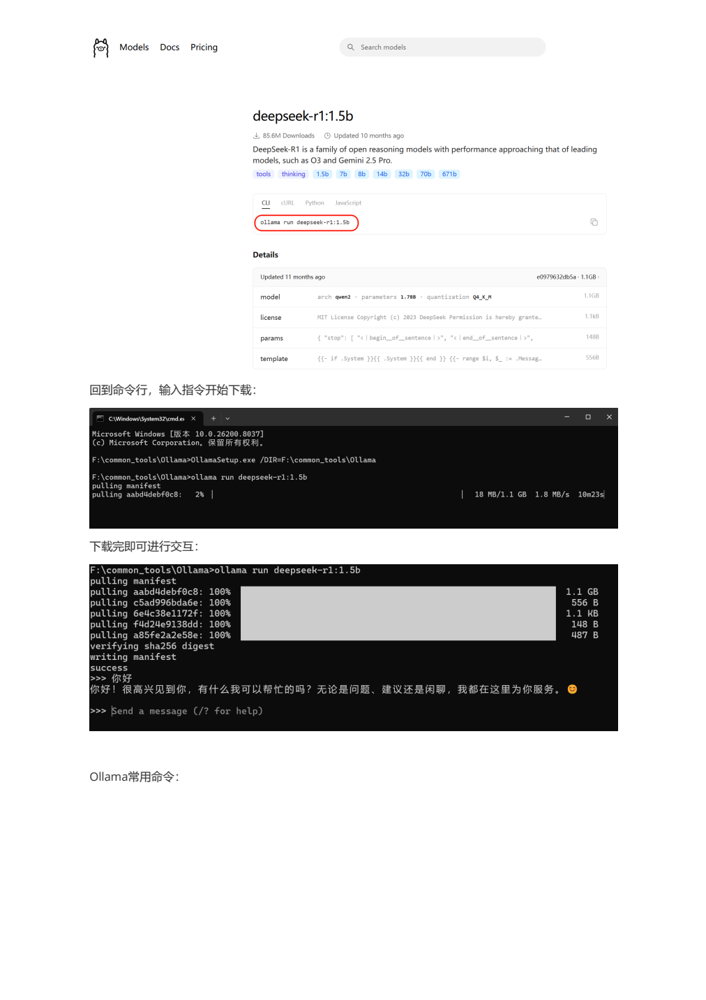


### 用 LangChain 调用 Ollama

~~~python
from langchain_ollama import ChatOllama

model = ChatOllama(
    model="deepseek-r1:1.5b",
    base_url="http://localhost:11434",
)

response = model.invoke("用一句话介绍人工智能")
print(response.content)
~~~

Ollama 模型也遵循聊天模型的统一调用方式，所以后面介绍的消息输入、流式调用、批量调用和异步方法同样可以迁移到本地模型。

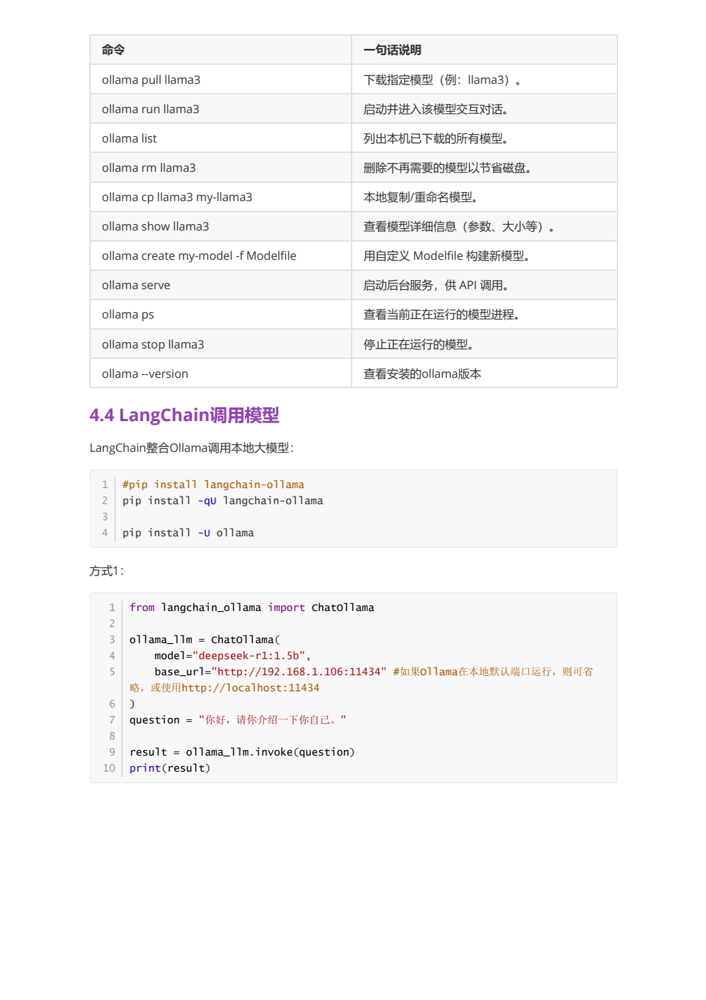


### 常用 Ollama 命令

| 命令 | 作用 |
| --- | --- |
| `ollama list` | 查看本机已有模型 |
| `ollama pull 模型名` | 下载模型 |
| `ollama run 模型名` | 在命令行运行模型 |
| `ollama rm 模型名` | 删除模型 |
| `ollama show 模型名` | 查看模型信息 |
| `ollama ps` | 查看正在运行的模型 |
| `ollama serve` | 启动本地服务（通常由安装程序管理） |

本地模型无法连接时，先确认服务地址、模型名和 Ollama 服务是否正在监听 `11434` 端口。


## 8. 模型调用方法

LangChain 聊天模型提供同步和异步两组方法：

| 方法 | 行为 | 典型场景 |
| --- | --- | --- |
| `invoke` | 等完整结果返回 | 普通问答、单次任务 |
| `stream` | 按片段返回结果 | 聊天界面、长文本生成 |
| `batch` | 一次提交多个输入 | 批量翻译、离线处理 |
| `ainvoke` | 异步等待一个结果 | 异步 Web 服务 |
| `astream` | 异步流式返回 | 异步聊天界面 |
| `abatch` | 异步批量处理 | IO 密集、高并发任务 |

流式和异步是否真正生效，还取决于供应商接口和网络客户端的支持。

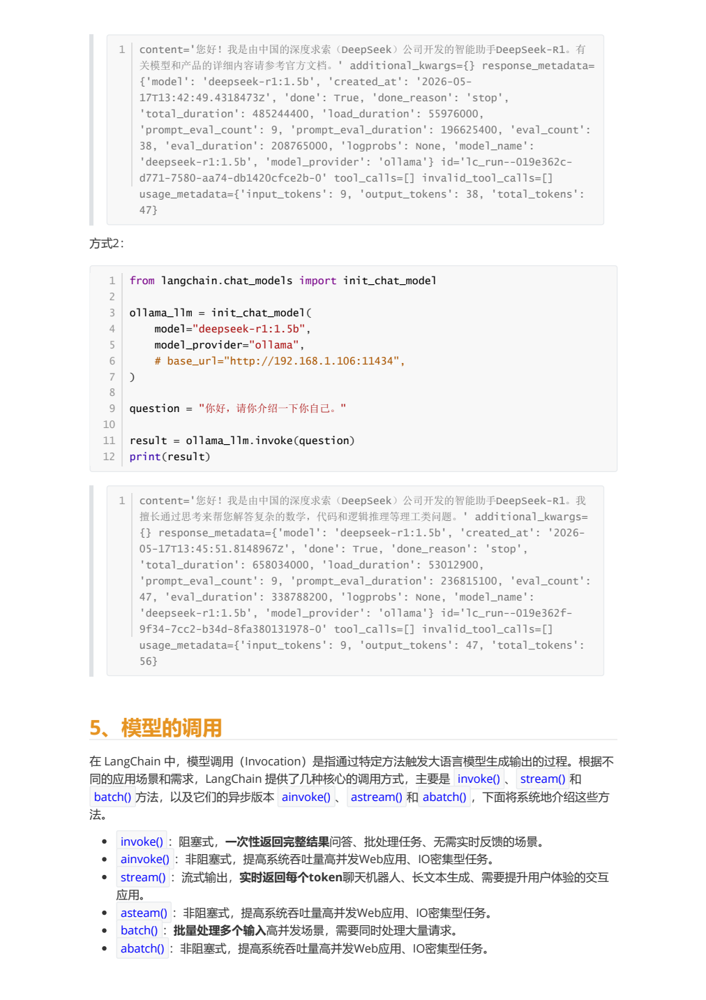

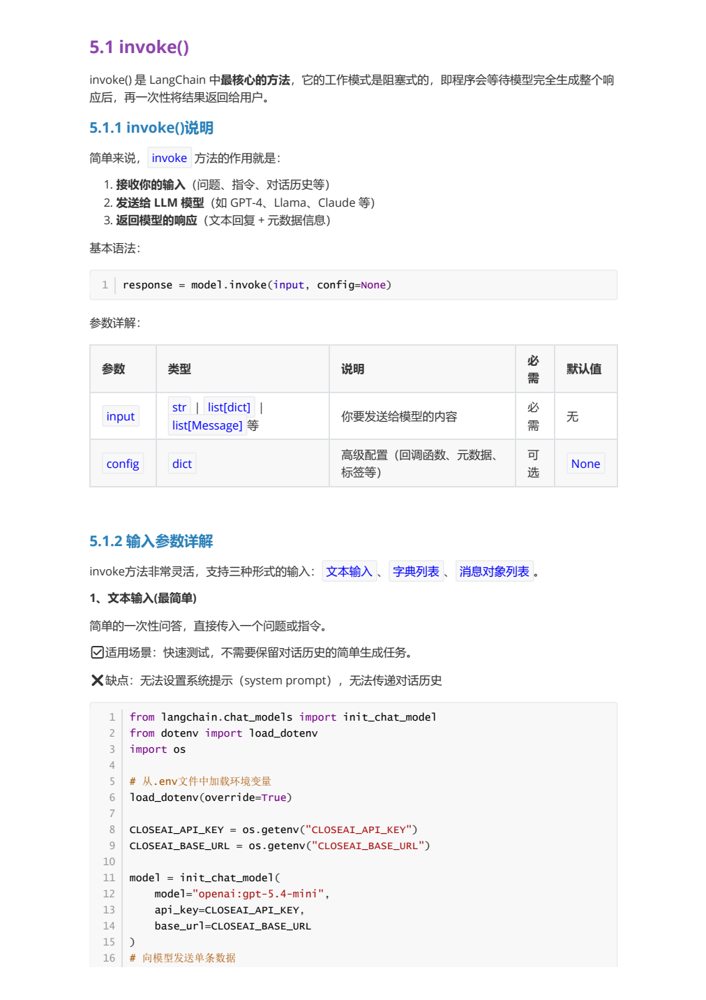


### `invoke`：一次返回完整结果

最简单的输入是字符串：

~~~python
response = model.invoke("翻译成英文：你好世界")
print(response.content)
~~~

`invoke` 会等待模型完成，再返回 `AIMessage`。这个对象除了 `content`，还可能包含 token 用量、模型名、停止原因、工具调用和响应 ID 等元数据。


### 三种输入形式

**1. 字符串**：适合快速测试，但不能显式表达系统提示和历史。

**2. 字典列表**：适合生产代码，易于序列化。

~~~python
messages = [
    {"role": "system", "content": "你是一个专业的数学老师。"},
    {"role": "user", "content": "什么是斐波那契数列？"},
]
response = model.invoke(messages)
~~~

**3. 消息对象列表**：适合需要类型和 IDE 提示的大型项目。

~~~python
from langchain_core.messages import SystemMessage, HumanMessage

messages = [
    SystemMessage(content="你是一个 Python 专家"),
    HumanMessage(content="什么是生成器？"),
]
response = model.invoke(messages)
~~~

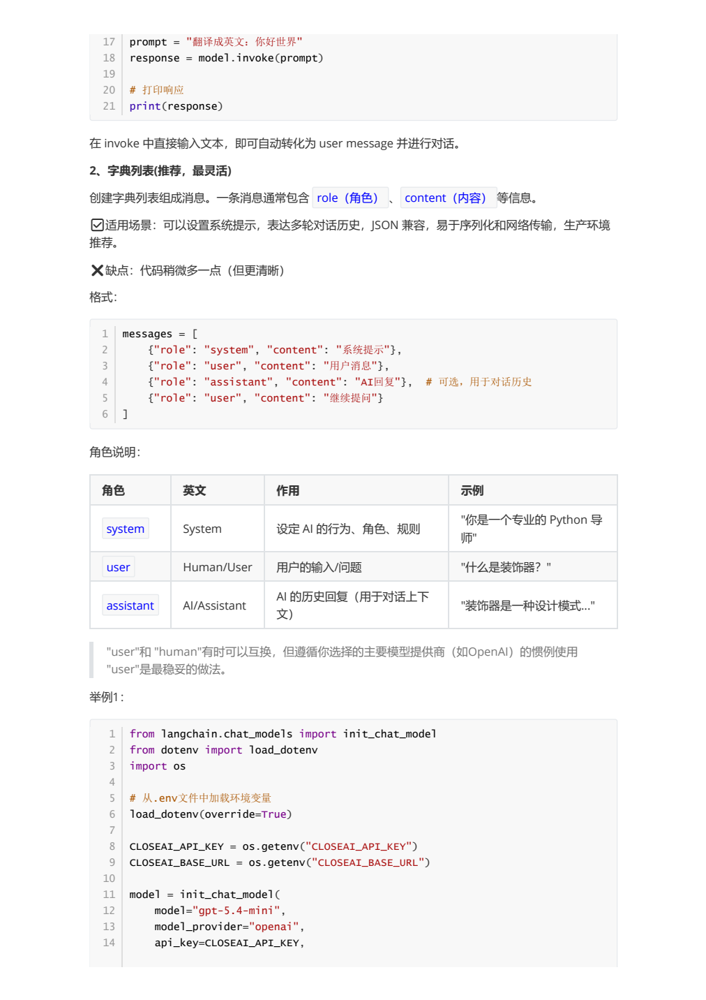

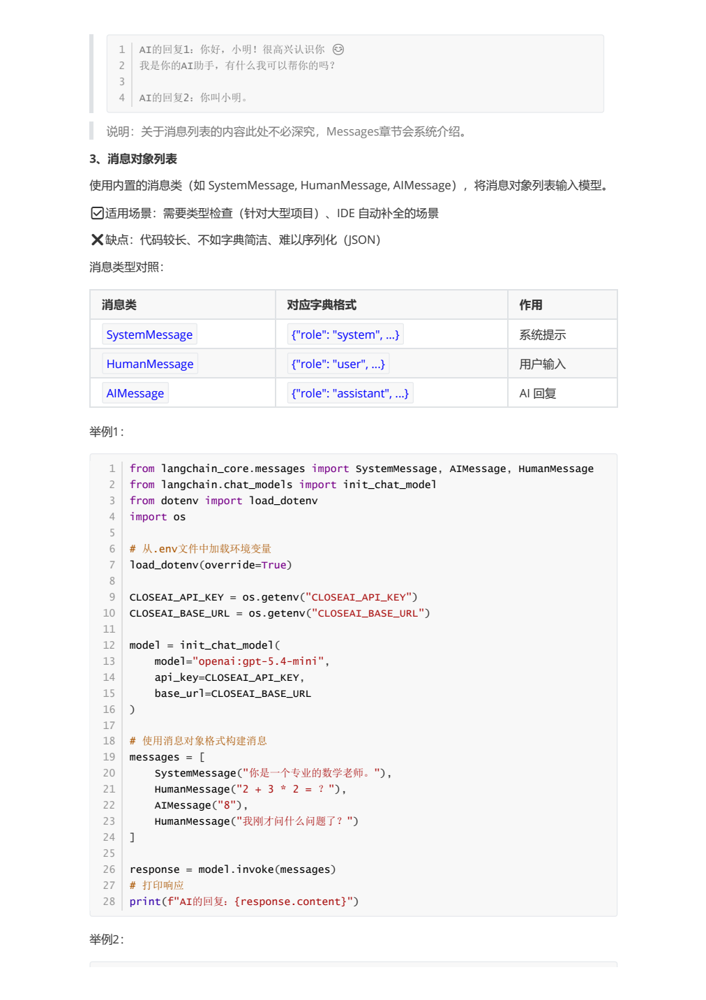

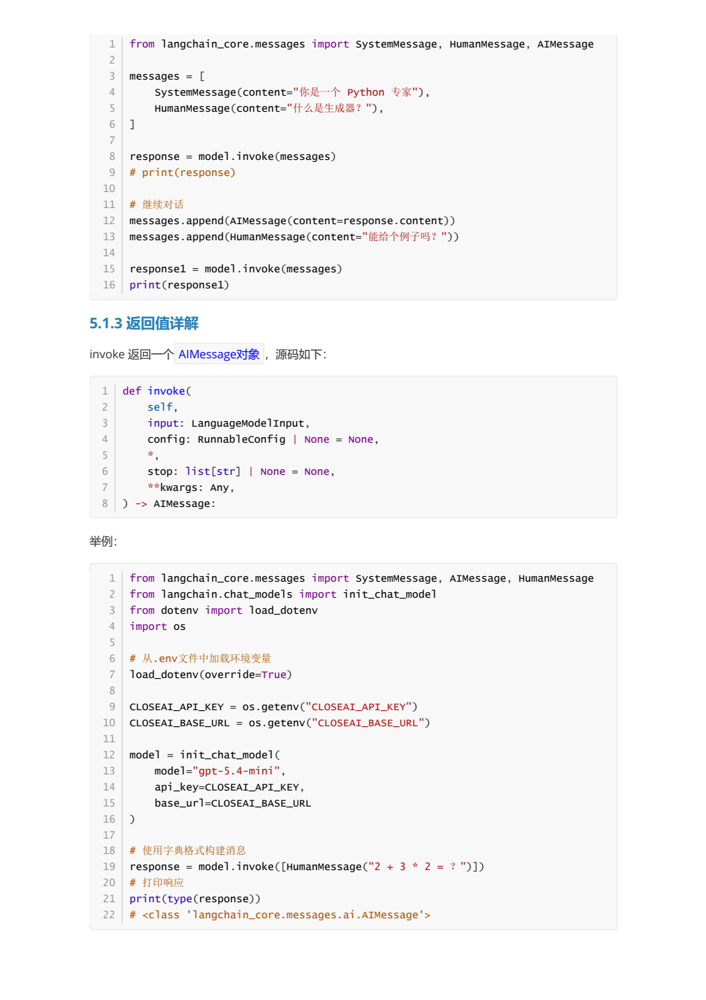


### 消息历史必须显式传入

模型调用本身通常是无状态的。第二次调用如果只传入新问题，模型看不到第一次调用的内容：

~~~python
first = model.invoke([{"role": "user", "content": "你好，我叫小明"}])
second = model.invoke([{"role": "user", "content": "我叫什么名字？"}])
~~~

要保留上下文，就把历史消息和新问题一起传入：

~~~python
conversation = [
    {"role": "user", "content": "你好，我叫小明"},
    {"role": "assistant", "content": first.content},
    {"role": "user", "content": "我叫什么名字？"},
]
second = model.invoke(conversation)
~~~

这只是“手动传历史”。真正的会话记忆还需要应用保存消息，后续章节会结合消息和记忆机制展开。


### 返回值：重点看 `content` 和元数据

`invoke` 返回的通常是 `AIMessage`，可以按需要读取：

~~~python
response = model.invoke("2 + 3 * 2 = ？")

print(response.content)             # 模型文本
print(response.response_metadata)   # 服务商响应元数据
print(response.usage_metadata)      # 输入/输出 token 统计（若供应商提供）
print(response.tool_calls)          # 工具调用列表（若模型触发工具）
~~~

不要把完整响应对象当成稳定的业务 JSON。不同供应商提供的元数据字段可能不同，业务逻辑通常只依赖 `content` 或标准化后的字段。

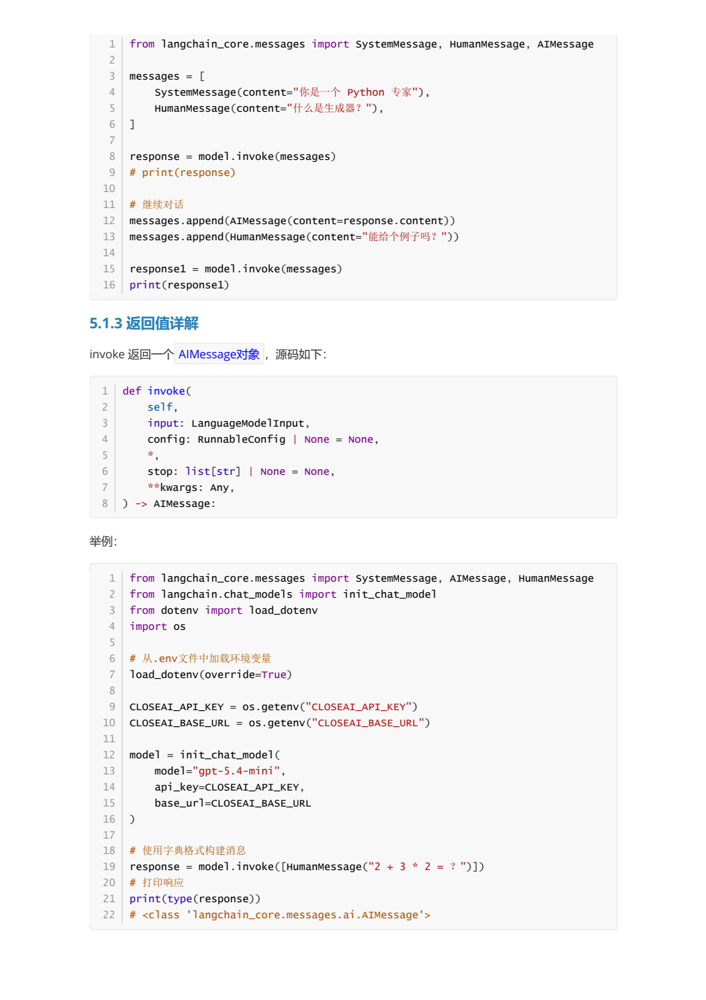

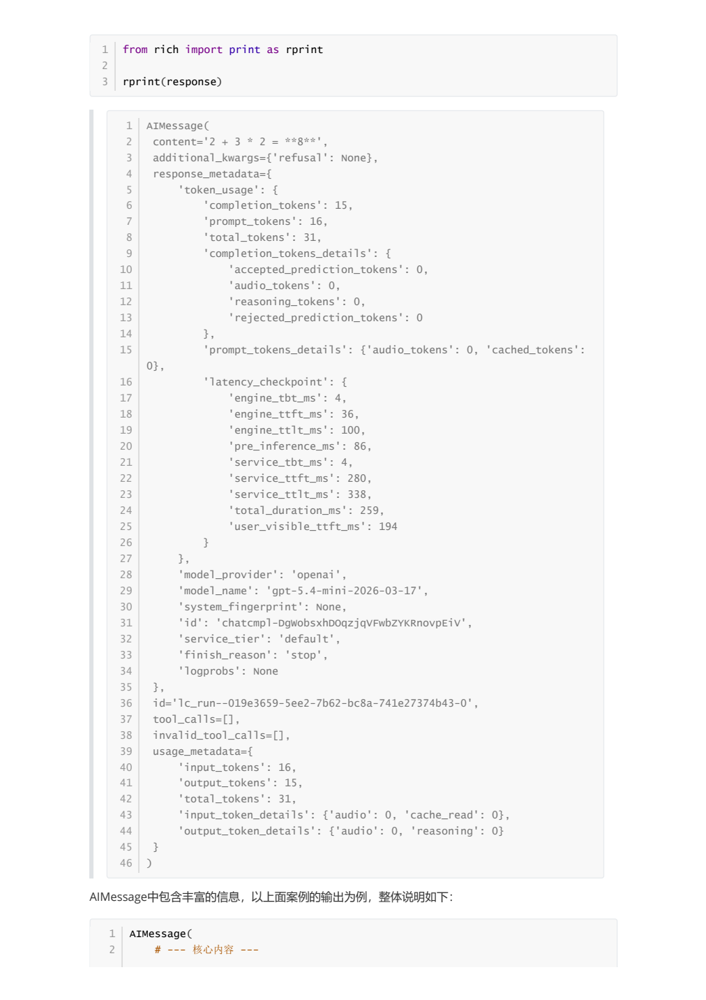

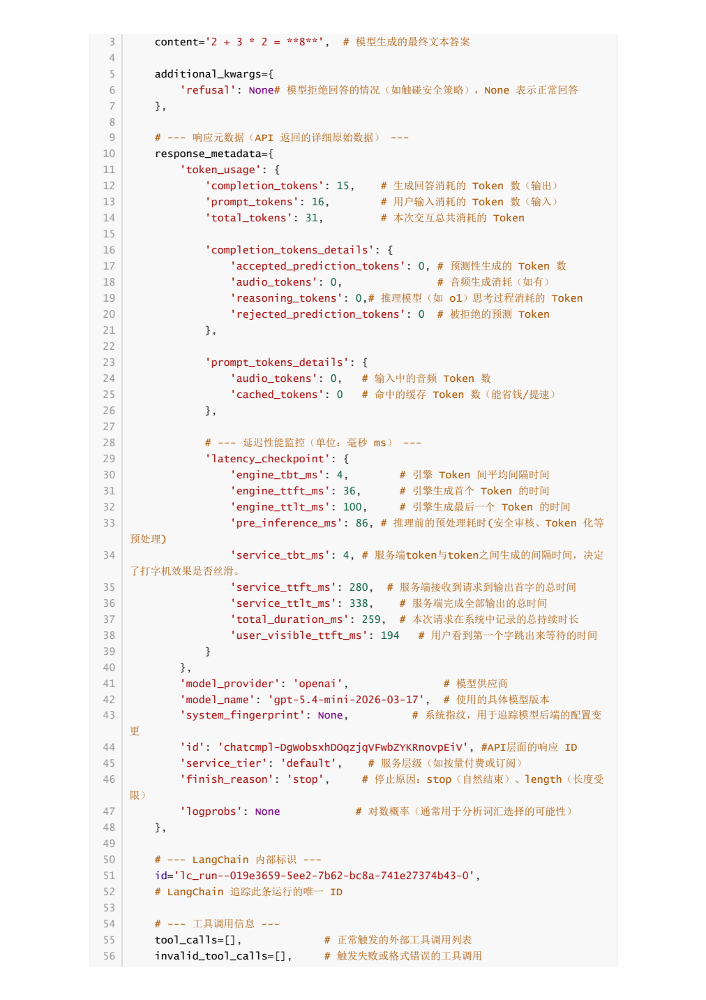

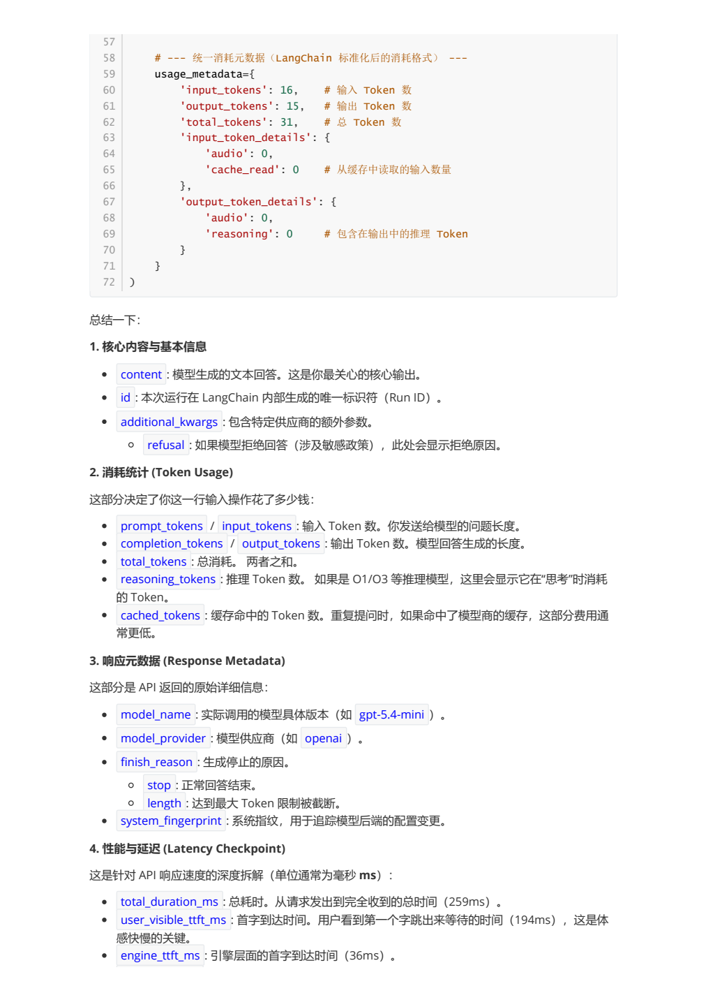


## 9. 流式、批量与异步调用

### `stream`：边生成边消费

~~~python
for chunk in model.stream("请用三句话介绍机器学习"):
    print(chunk.content, end="", flush=True)
~~~

每个 `chunk` 通常是消息片段，不一定包含完整的响应元数据。界面可以立刻显示文本，任务结束后再收集完整结果或记录最终用量。

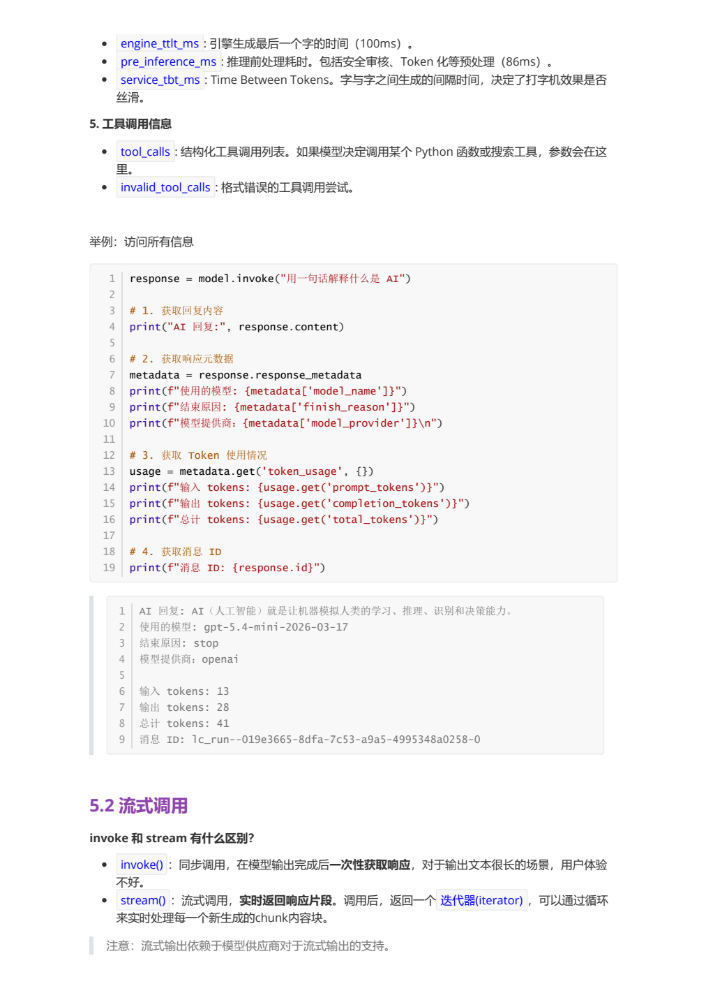

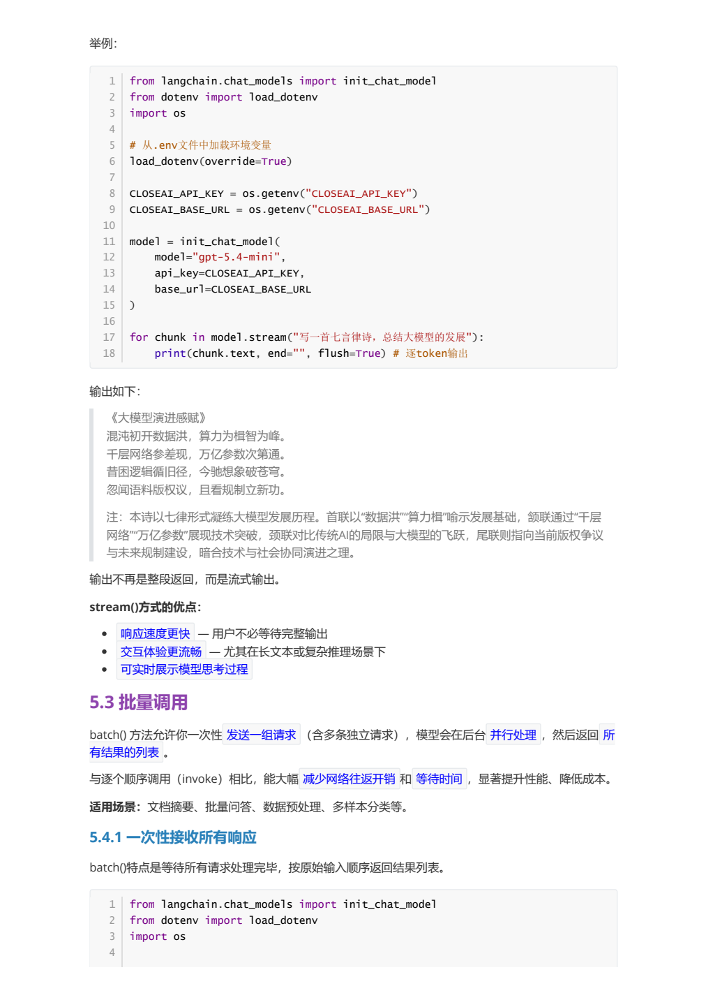


### `batch`：一次处理多个输入

~~~python
questions = [
    "中国的首都在哪里？",
    "用一句话解释深度学习。",
]

responses = model.batch(questions)
for response in responses:
    print(response.content)
~~~

`batch` 的结果通常按输入顺序返回。它适合离线批处理；如果需要按哪个任务先完成就先消费，可以使用异步批量接口的完成顺序版本，并为每个输入保留索引。


### 异步方法：不要阻塞事件循环

~~~python
import asyncio

async def main():
    response = await model.ainvoke("用一句话解释异步调用")
    print(response.content)

asyncio.run(main())
~~~

异步方法适合异步 Web 服务和多个 IO 请求并发。`asyncio.sleep()` 可以让出事件循环；在异步函数中使用阻塞的 `time.sleep()` 会拖住其他任务。

异步流式和批量调用的形态：

~~~python
async for chunk in model.astream("介绍机器学习"):
    print(chunk.content, end="")

responses = await model.abatch(["问题一", "问题二"])
~~~

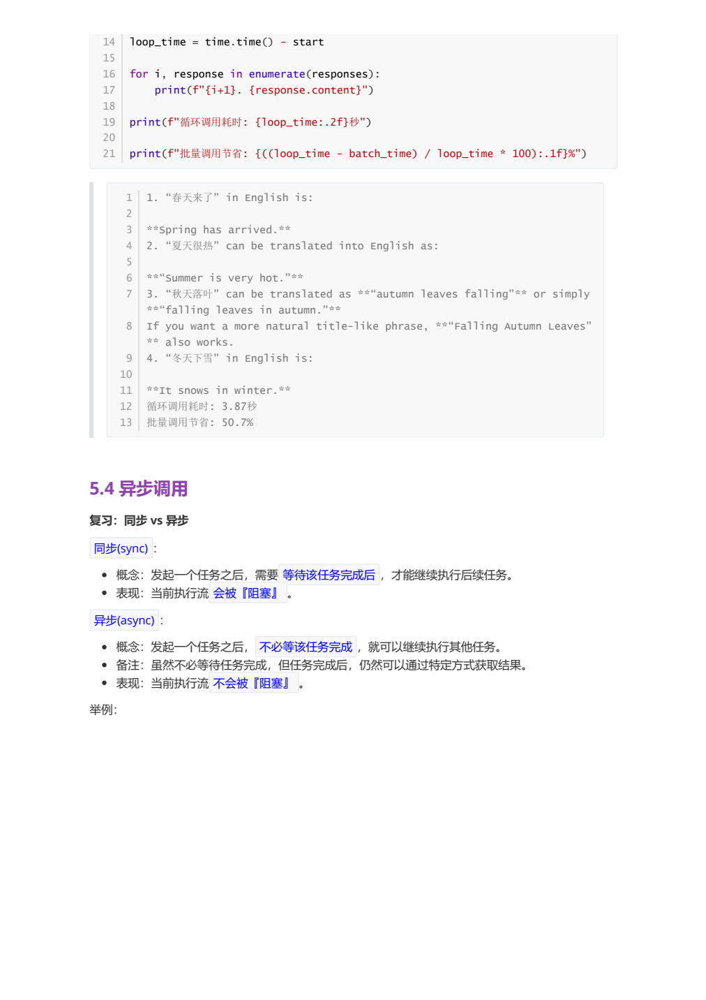

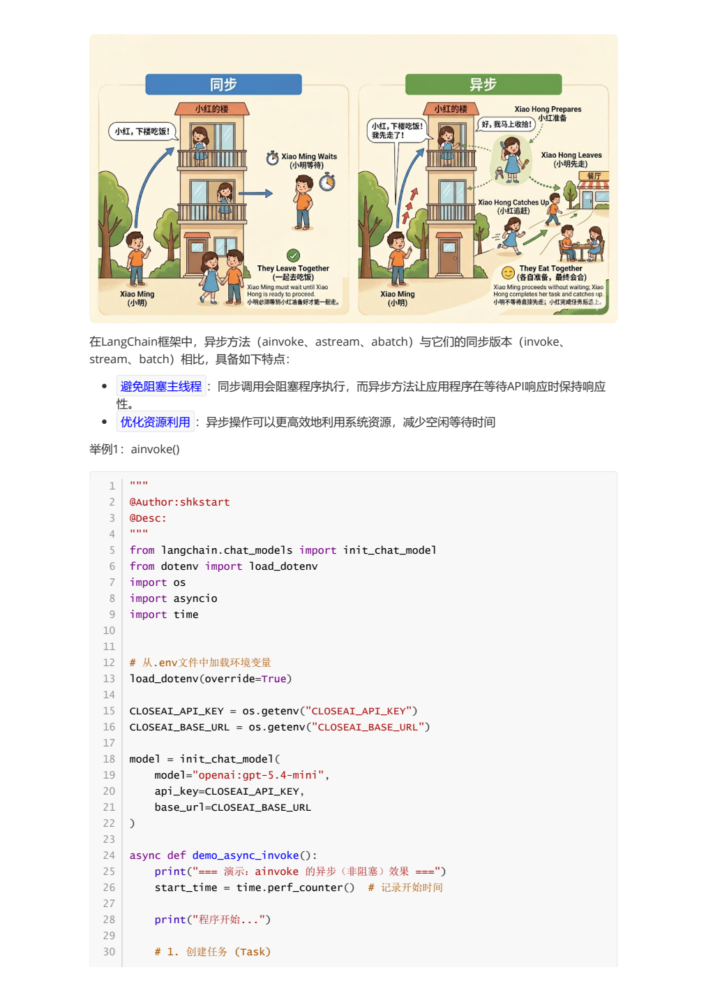

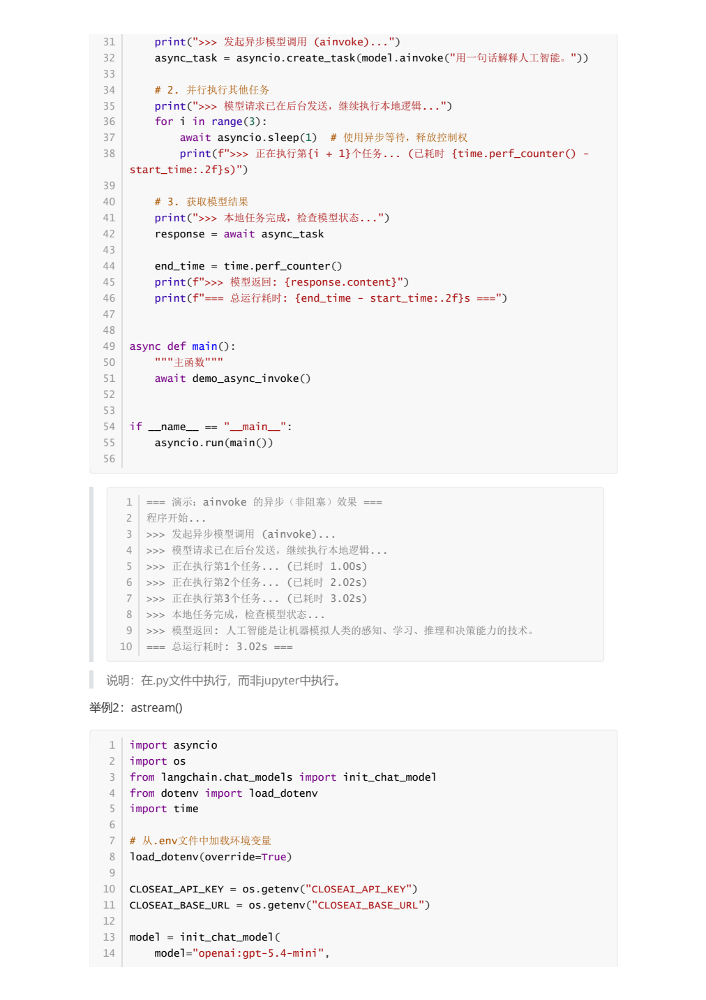

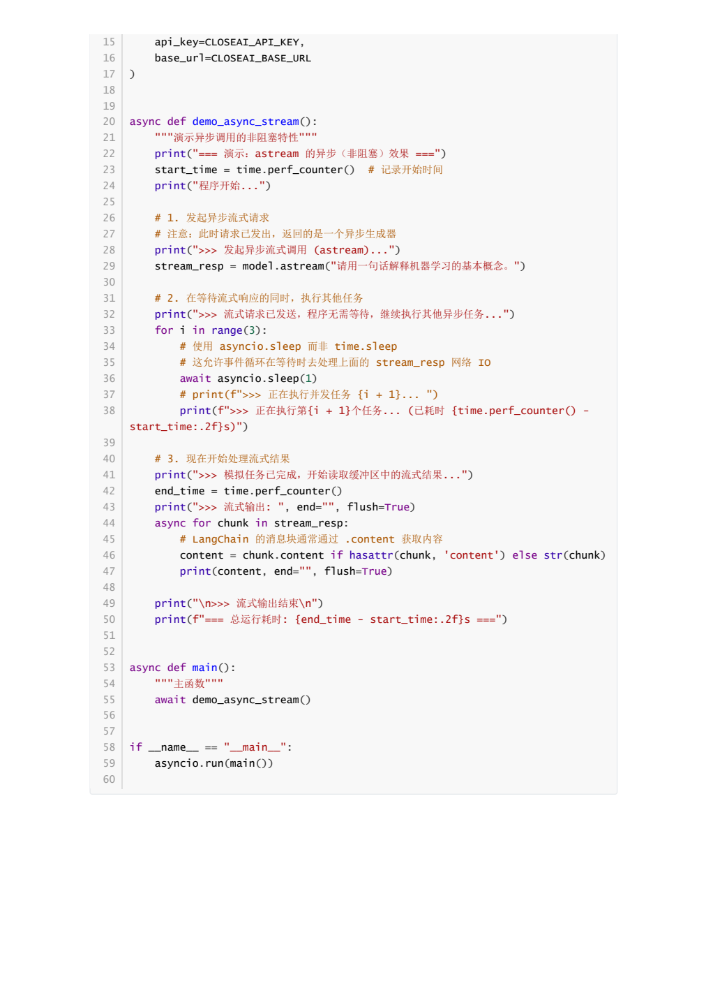

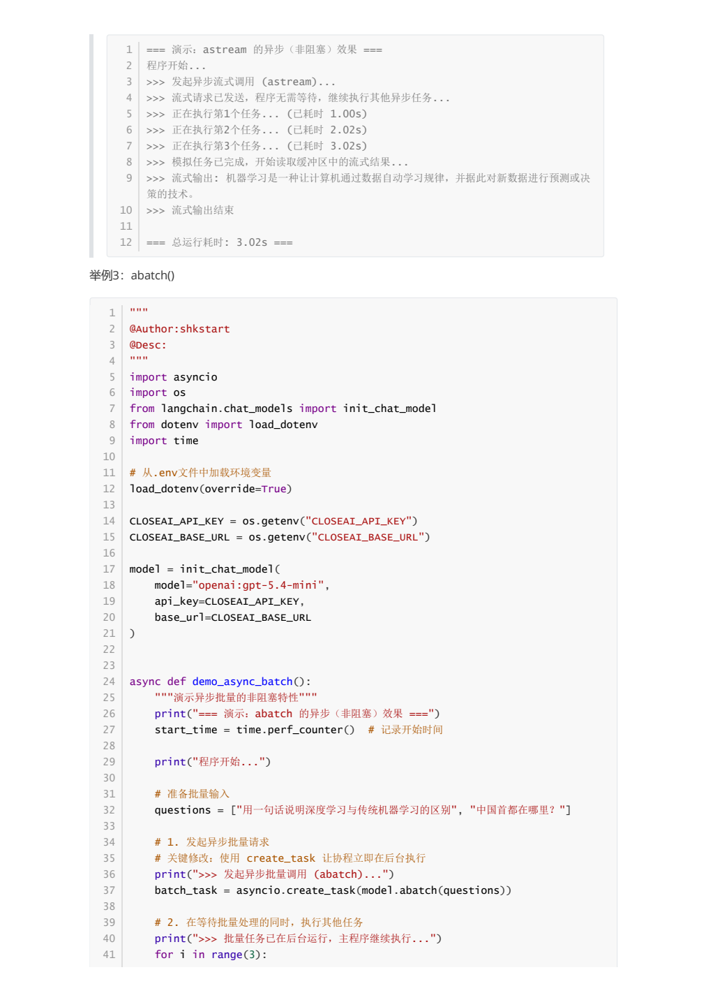

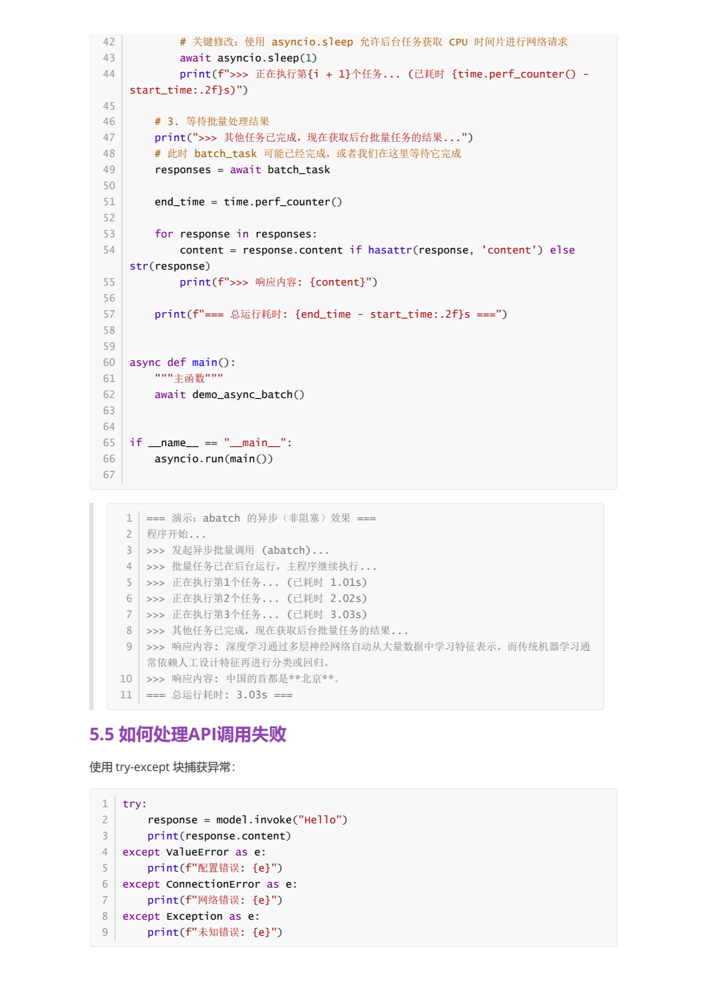


### API 失败处理

网络超时、认证错误、速率限制和供应商服务故障都可能导致调用失败。应用需要区分配置错误、网络错误和可重试错误：

~~~python
try:
    response = model.invoke("Hello")
except ValueError as exc:
    print(f"配置或参数错误：{exc}")
except ConnectionError as exc:
    print(f"网络连接错误：{exc}")
except Exception as exc:
    print(f"其他错误：{exc}")
~~~

生产环境还应设置 `timeout`、合理的 `max_retries`、限流和日志脱敏。不要在日志里打印 API Key 或完整用户隐私数据。


## 10. profile、完整参数和扩展字段

### 模型能力画像 `profile`

部分 LangChain 集成会在 `model.profile` 中声明模型能力，例如最大输入长度、是否支持图片、工具调用或结构化输出：

~~~python
print(model.profile)
~~~

空字典不代表模型一定没有能力，只表示当前集成没有声明能力画像。画像可能随着集成包和模型 ID 变化，不能替代供应商官方文档。

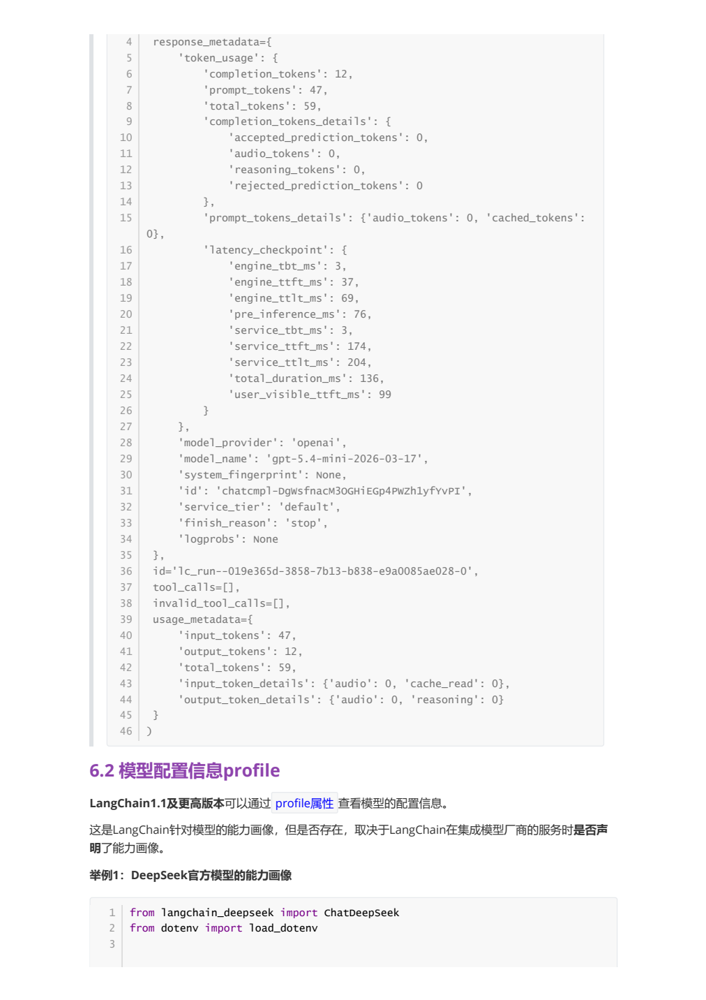

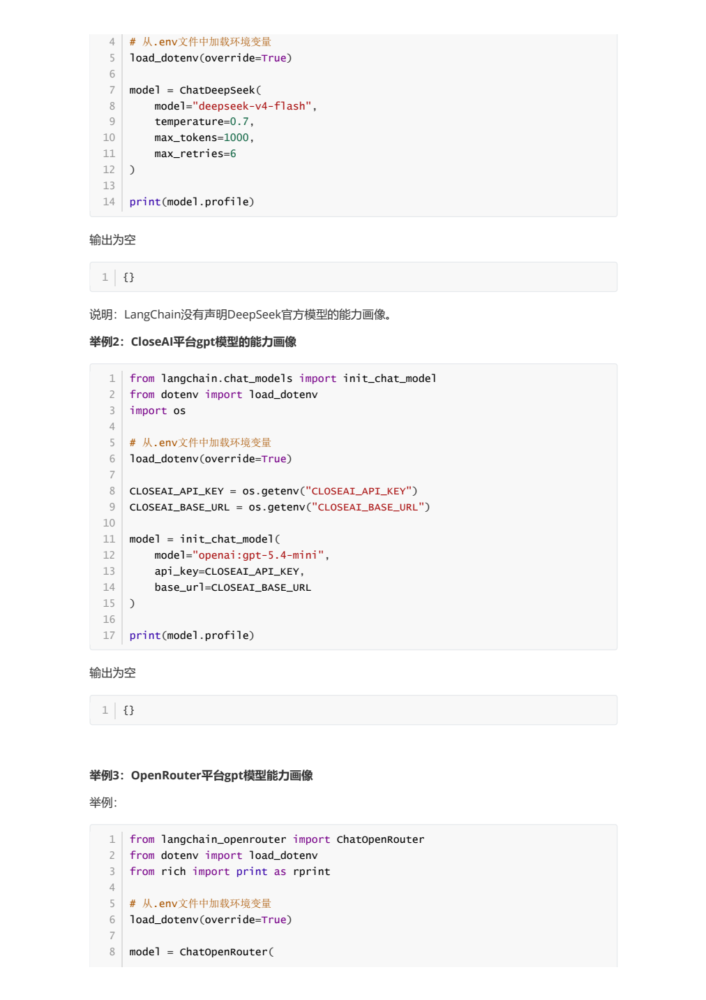

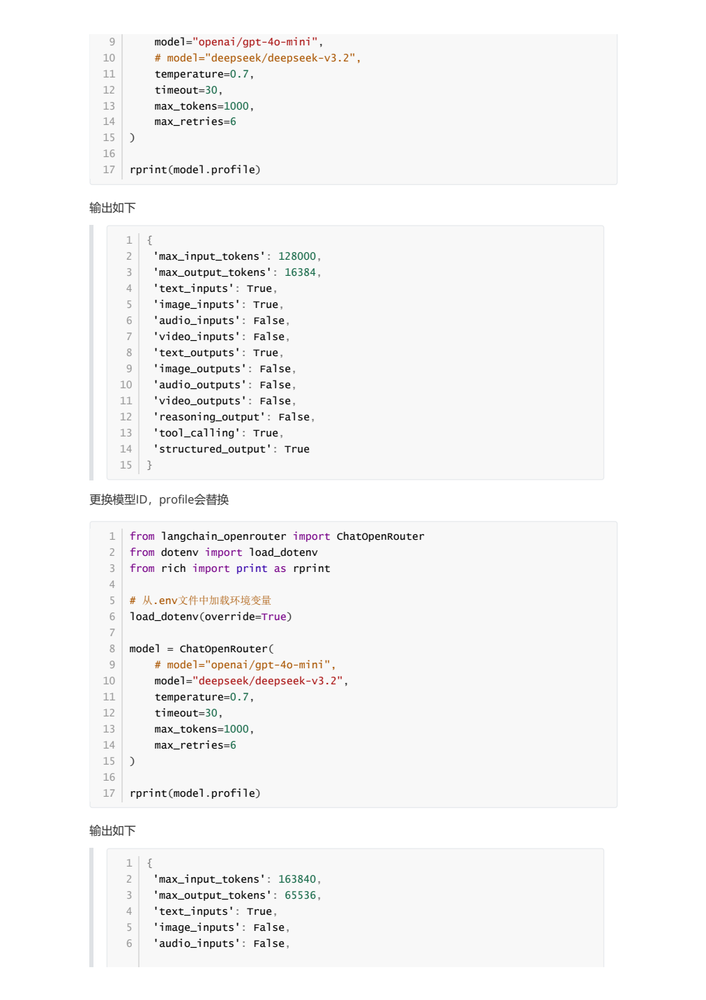

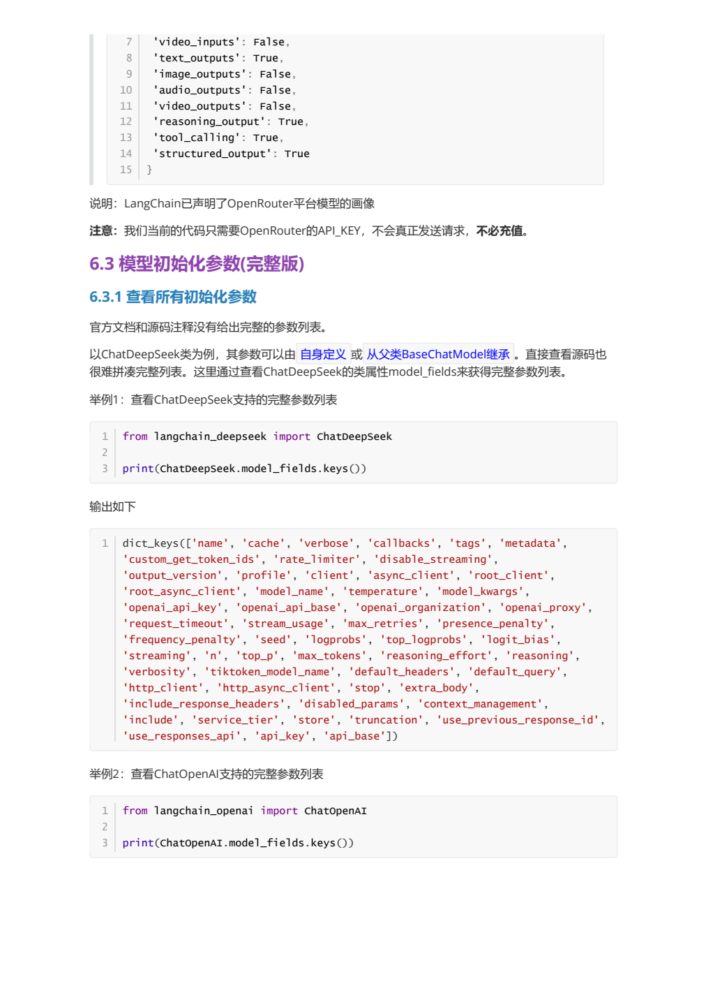


### 查看模型类支持的字段

基于 Pydantic 的模型类通常可以查看 `model_fields`：

~~~python
from langchain_deepseek import ChatDeepSeek

print(ChatDeepSeek.model_fields.keys())
~~~

这些字段大致分为：

| 类别 | 例子 | 作用 |
| --- | --- | --- |
| 连接参数 | `api_key`、`api_base`、`timeout` | 决定怎样连接服务 |
| 推理参数 | `model`、`temperature`、`top_p`、`max_tokens` | 决定生成风格和长度 |
| LangChain 通用参数 | `callbacks`、`tags`、`metadata`、`cache` | 追踪、缓存和运行管理 |
| 扩展参数 | `model_kwargs`、`extra_body` | 传递集成类未显式声明的供应商字段 |

不要把内部客户端字段当成业务配置；通常只设置文档明确支持的公共参数。

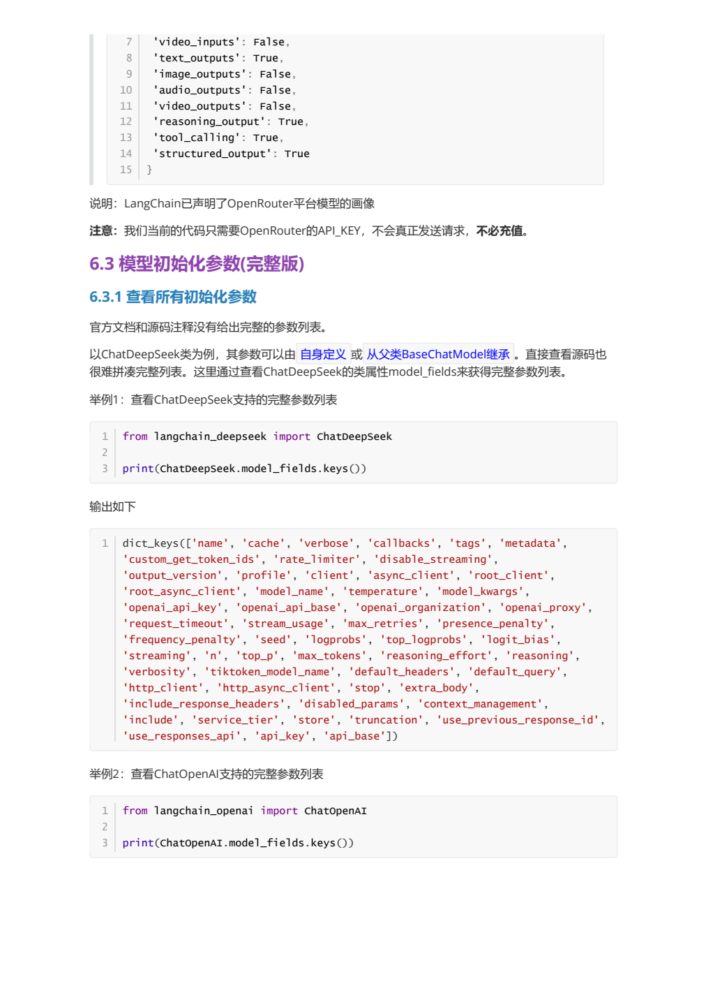

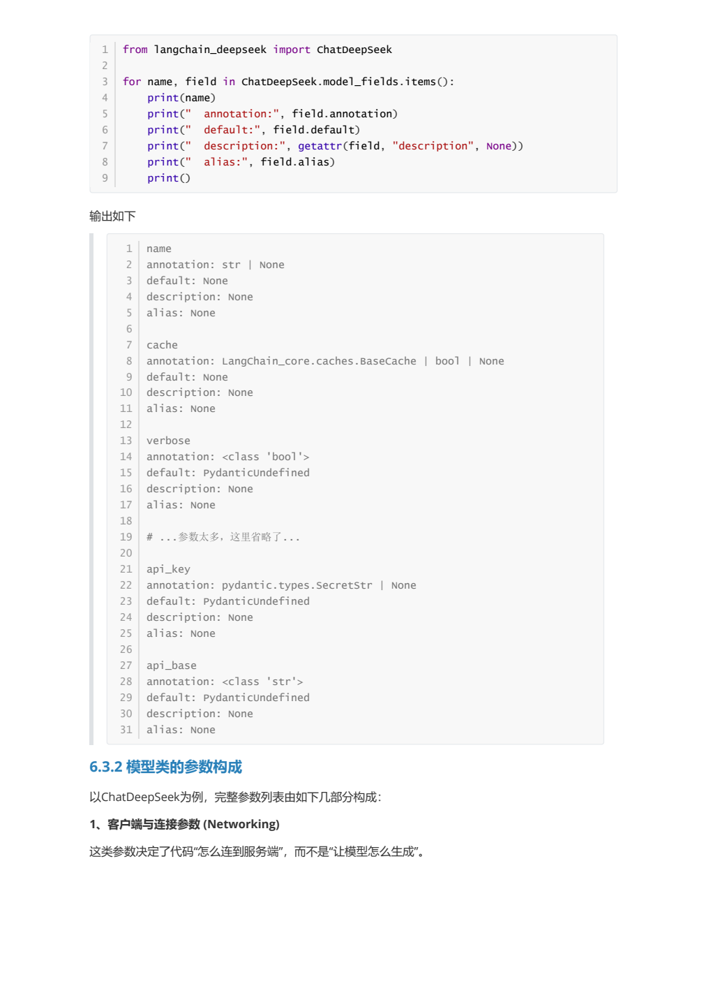

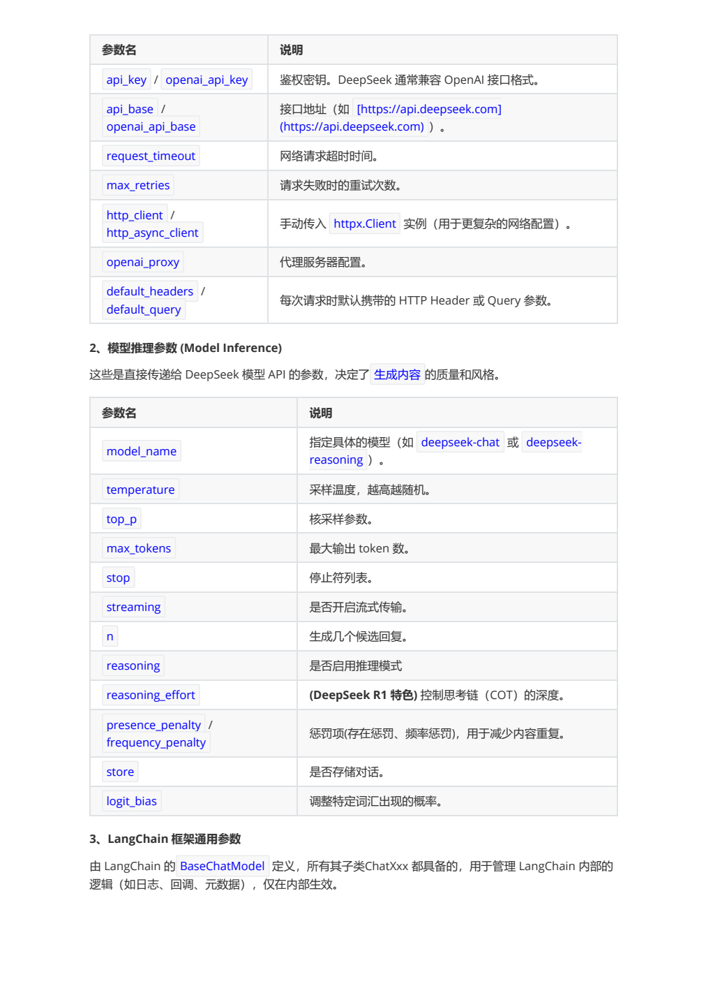

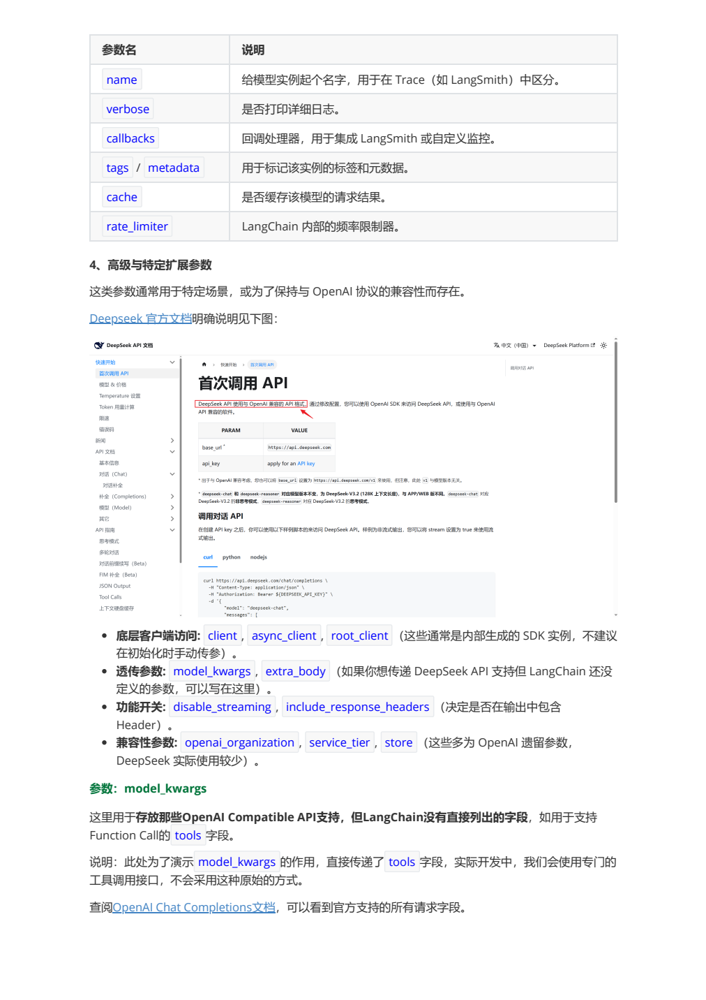


### `model_kwargs` 与 `extra_body`

`model_kwargs` 通常用于兼容协议中模型请求字段；`extra_body` 常用于供应商扩展字段，例如某些模型的思考模式开关。

~~~python
model = init_chat_model(
    model="deepseek:deepseek-v4-flash",
    extra_body={"thinking": {"type": "enabled"}},
)
~~~

课程还演示了用 `model_kwargs` 手动放入工具定义。实际项目优先使用 `bind_tools()` 或 Agent 工具接口，因为标准接口更容易验证参数、处理工具调用和跨模型迁移。

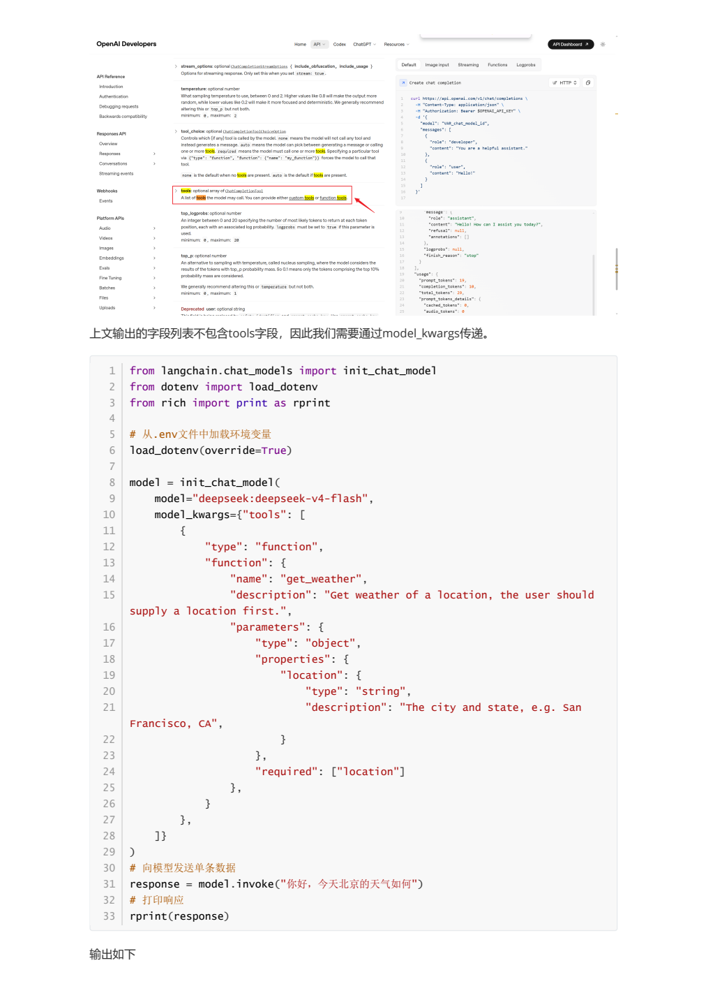

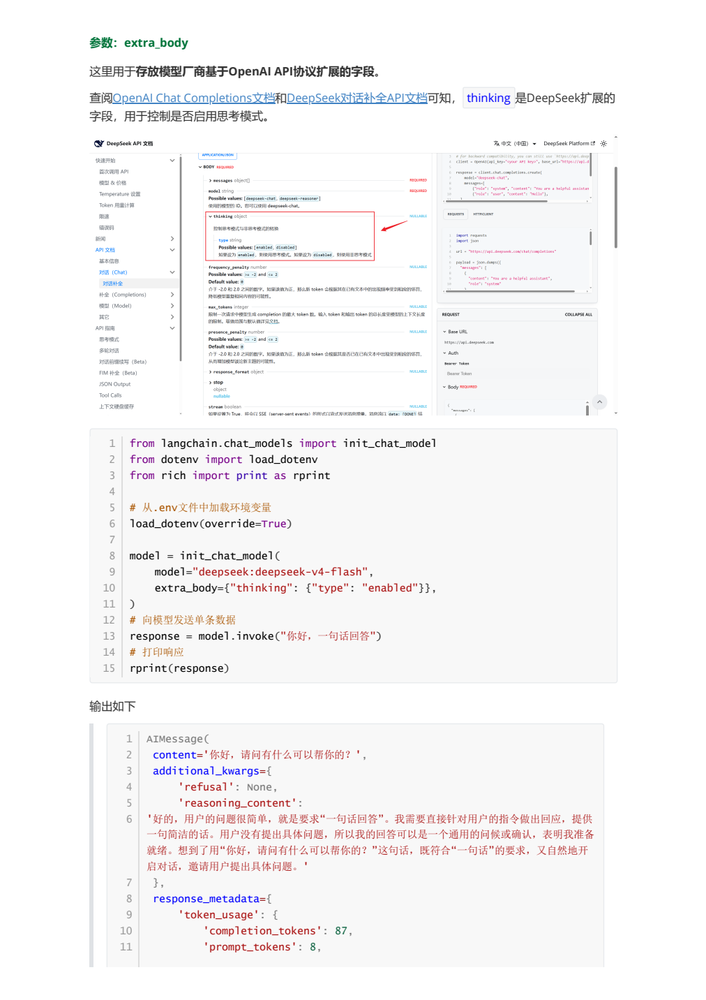


## 11. 调用时的 `config`

`config` 是运行时配置，不是模型初始化参数。它可以为某一次调用附加运行名、标签、元数据、回调、并发限制和可配置字段。

~~~python
response = model.invoke(
    "你好",
    config={
        "run_name": "greeting",
        "tags": ["demo"],
        "metadata": {"user_id": "123"},
        "max_concurrency": 5,
    },
)
~~~

常用字段：

| 字段 | 用途 |
| --- | --- |
| `run_name` | 给本次运行起可读名称 |
| `tags` | 给运行分类、过滤 |
| `metadata` | 记录用户或业务上下文 |
| `callbacks` | 接入自定义回调和观测系统 |
| `max_concurrency` | 限制并发运行数 |
| `recursion_limit` | 限制递归工作流深度 |
| `configurable` | 给支持动态配置的 Runnable 传值 |

例如批量请求时限制并发：

~~~python
responses = model.batch(
    many_inputs,
    config={"max_concurrency": 5},
)
~~~

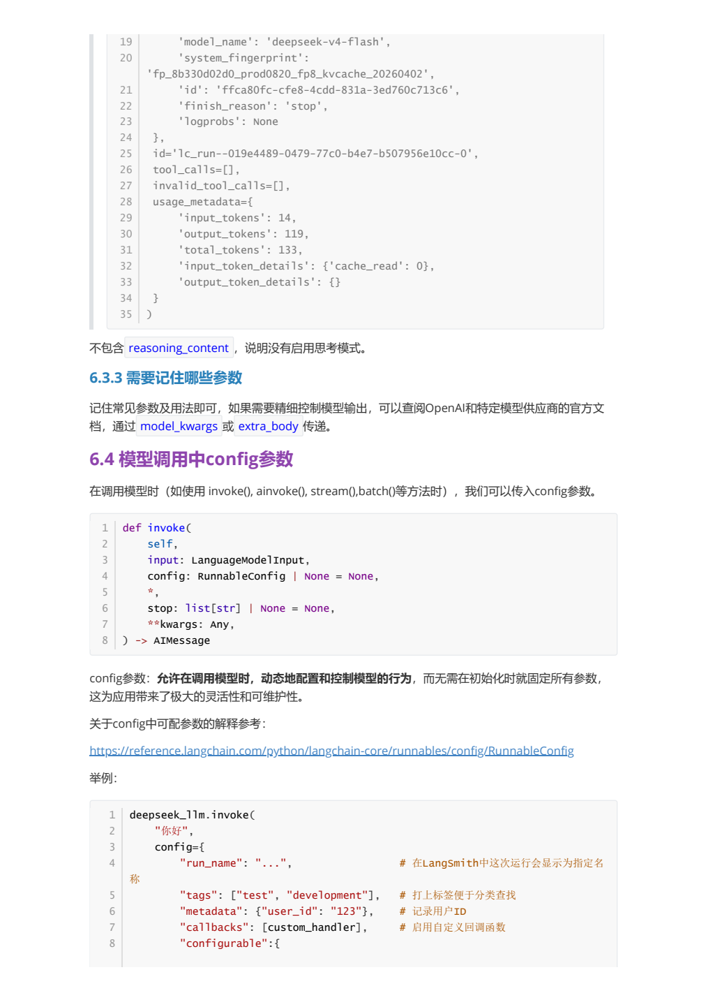

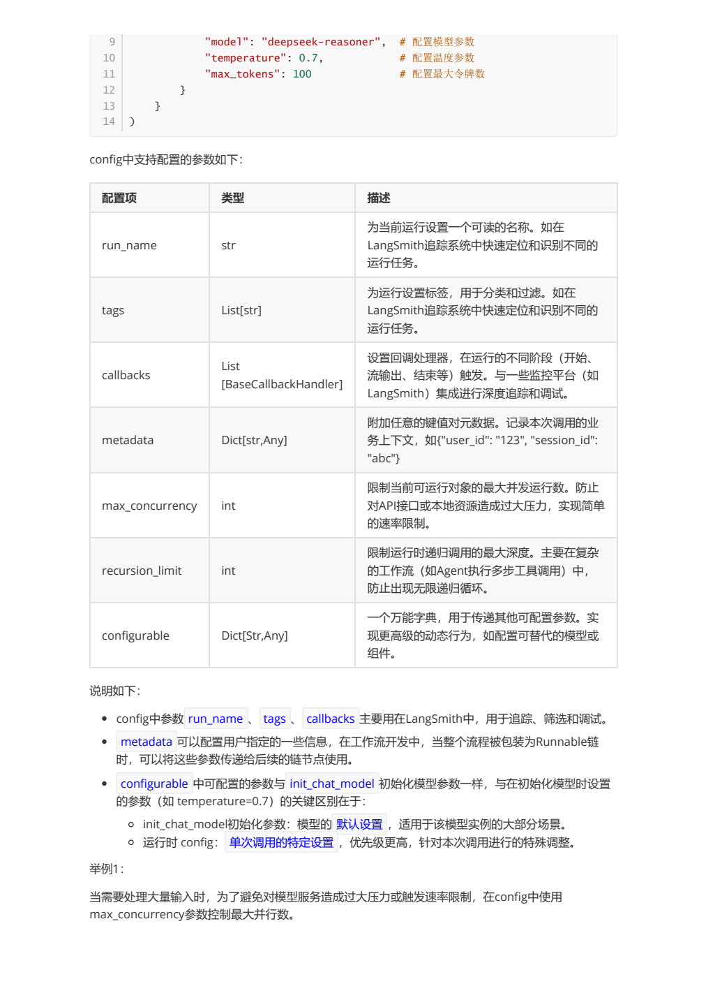

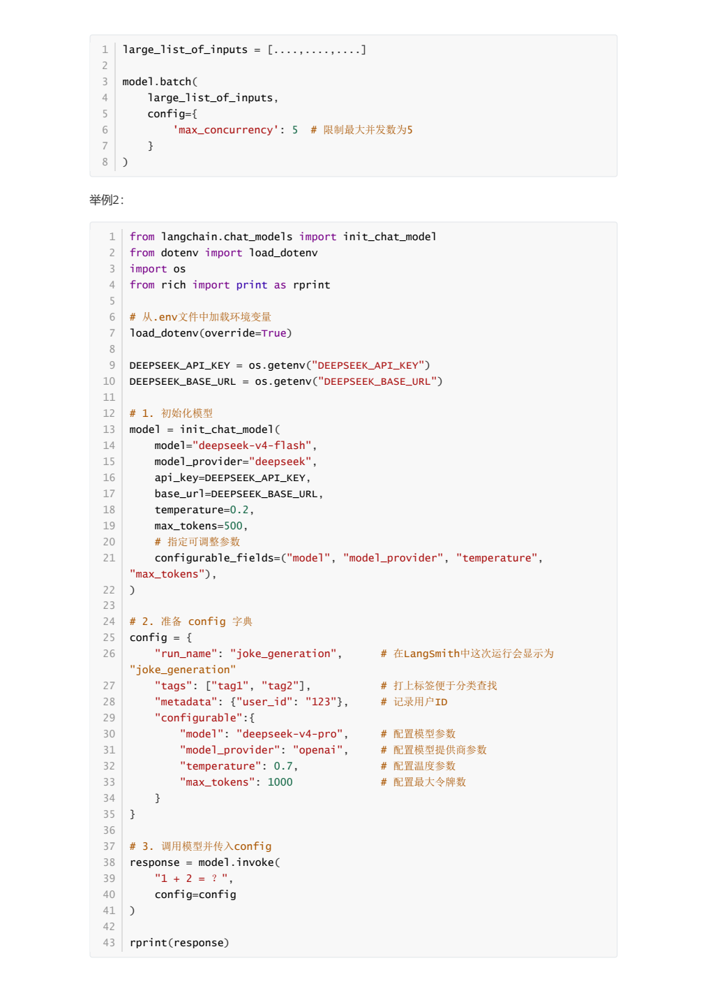


## 复习：如何选择模型创建和调用方式？

| 需求 | 选择 |
| --- | --- |
| 需要供应商专属参数或能力 | 使用对应的 `ChatXxx` 专用类 |
| 平台遵循 OpenAI 协议 | 使用 `ChatOpenAI` + `base_url` |
| 需要在多个模型间切换 | 使用 `init_chat_model` 或外部配置 |
| 离线运行或隐私优先 | 使用 `ChatOllama` 等本地集成 |
| 普通一次问答 | `invoke` |
| 用户界面实时显示 | `stream` / `astream` |
| 多个输入一起处理 | `batch` / `abatch` |
| 需要观测和并发控制 | 调用时传 `config` |

**面试提示**：模型调用本身通常无状态，历史消息要由调用方显式传入或由记忆组件保存；`stream` 解决“尽快看到输出”，`batch` 解决“同时处理多个输入”，异步方法解决“等待 IO 时不阻塞事件循环”。
